In [10]:
# plots the light curve of the objects that haven't pass through all three classifiers that we run.
import io
import requests as re
import pandas as pd


def collect_light_curve_data(diaObjectId):
    r = re.post(
        "https://api.lsst.fink-portal.org/api/v1/sources",
        json={
            "diaObjectId": diaObjectId,
            "columns": "r:diaObjectId, r:diaSourceId,r:midpointMjdTai,r:psfFlux,r:psfFluxErr, r:band",
            "output-format": "json",
        },
    )
    if r.status_code != 200:
        print (f"Failed to fetch the light curve info for {diaObjectId}: {r.status_code}")
        return None
    return pd.read_json(io.BytesIO(r.content))

['extragalactic\nlt20mag', 'extragalactic\nnew', 'sn near\ngalaxy']


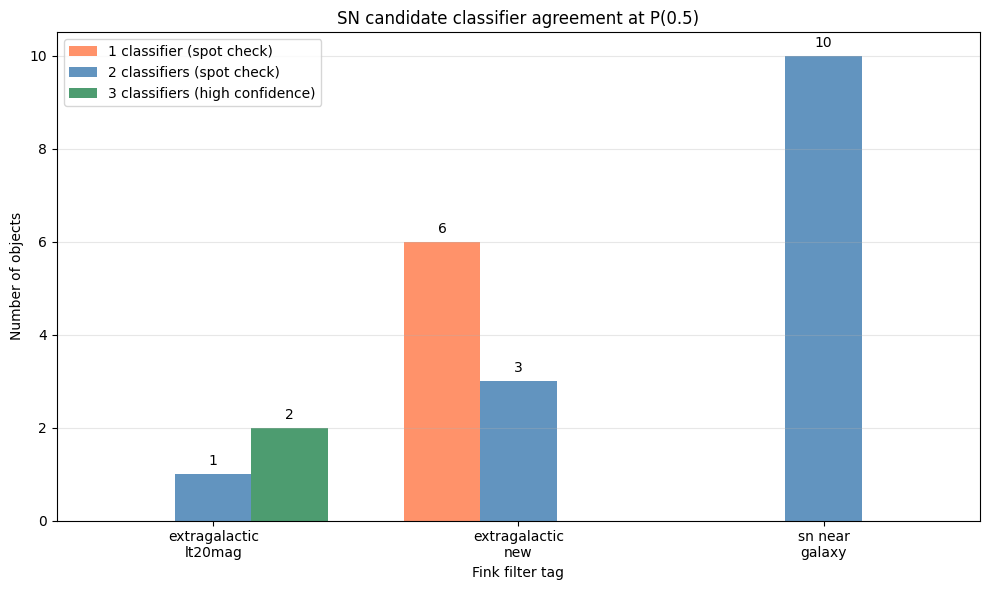

In [ ]:
# generated using Claude Sonnet 4.6 adaptive with the following prompt: "Now with the objects and their classification scores, 
# could you help me generate a plot that shows the number of objects from the acquisition pipeline that passed three, two or one classifier score cuts please?"

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

base_classified_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_classified")
classified_csv_files = {
    "extragalactic\nlt20mag":    base_classified_path / "extragalactic_lt20mag_candidates_classified.csv",
    "extragalactic\nnew":        base_classified_path / "extragalactic_new_candidate_classified.csv",
    "sn near\ngalaxy":           base_classified_path / "sn_near_galaxy_candidate_classified.csv",
}

threshold = 0.5

# Count objects per tier per filter
tier_counts = {label: {1: 0, 2: 0, 3: 0} for label in classified_csv_files}

for label, path in classified_csv_files.items():
    df = pd.read_csv(path, dtype={"r:diaObjectId": str})

    mask_CATS      = (df["clf_cats_class_mode"] == 11) & (df["clf_cats_score_max"] > threshold)
    mask_EarlySNIa = df["clf_earlySNIa_max"] > threshold
    mask_snn       = df["clf_snn_max"] > threshold

    df_candidates = df[mask_CATS | mask_EarlySNIa | mask_snn].copy()
    df_candidates["n_classifiers_agree"] = (
        (df_candidates["clf_cats_score_max"] > threshold).astype(int) +
        (df_candidates["clf_earlySNIa_max"]  > threshold).astype(int) +
        (df_candidates["clf_snn_max"]        > threshold).astype(int)
    )

    for tier in [1, 2, 3]:
        tier_counts[label][tier] = len(df_candidates[df_candidates["n_classifiers_agree"] == tier])

# Plot
labels = list(tier_counts.keys())
n1 = [tier_counts[l][1] for l in labels]
n2 = [tier_counts[l][2] for l in labels]
n3 = [tier_counts[l][3] for l in labels]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width, n1, width, label="1 classifier (spot check)", color="coral",    alpha=0.85)
bars2 = ax.bar(x,          n2, width, label="2 classifiers (spot check)", color="steelblue", alpha=0.85)
bars3 = ax.bar(x + width,  n3, width, label="3 classifiers (high confidence)", color="seagreen", alpha=0.85)

# Add count labels on top of each bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(f"{int(height)}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10)

ax.set_xlabel("Fink filter tag")
ax.set_ylabel("Number of objects")
ax.set_title(f"SN candidate classifier agreement at P({threshold})")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("classifier_agreement.png", dpi=150)
plt.show()

Saved to: C:\Users\riley\Documents\University\Honours\Honours_Project\images\standup_1-06-2026_alert_comparison.png


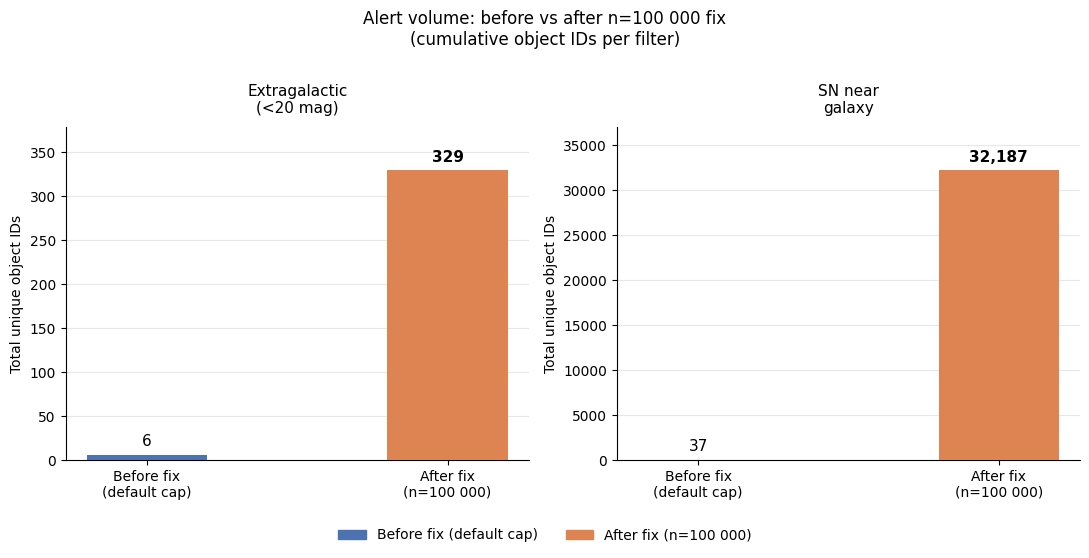

In [3]:
# Generated by: Anthropic Claude (model: claude-sonnet-4-6)
# Prompt: "Today I have a stand up meeting where I want to include the massive increase in
# alerts I now have because of the fix to the Id collection file that we made on Friday last
# week. I want to display the total number of objects I was getting with the previous filter
# before we made the changes to the n: 100000 variable in accessing the alerts. I am thinking
# bar plot with the two original filters (extragalactic with the magnitude cut and the
# SN_near galaxy_candidate) and compare them to the new variants with the number of alerts
# variable explicitly stated. Could we make those plots?"

"""
Standup bar chart: object counts before vs after the n=100000 fix.

Before fix: default API pagination cap was hit (n not explicitly set),
so counts were truncated. After fix: n=100000 explicitly passed,
pulling the full alert volume.

Reads the current CSVs for "after" counts. You supply the "before" counts
manually below (from your notes / previous run logs).
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from pathlib import Path

# ── paths ────────────────────────────────────────────────────────────────────
base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids")

csv_files = {
    "extragalactic_lt20mag": base_path / "extragalactic_lt20mag_candidate.csv",
    "sn_near_galaxy":        base_path / "sn_near_galaxy_candidate.csv",
}

# ── before counts: fill these in from your pre-fix run ───────────────────────
# (replace 0s with the actual numbers from Friday's logs)
before_counts = {
    "extragalactic_lt20mag": 6,
    "sn_near_galaxy":        37,
}

# ── read after counts from CSVs ───────────────────────────────────────────────
after_counts = {}
for tag, path in csv_files.items():
    if path.exists():
        df = pd.read_csv(path, dtype={"diaObjectId": str})
        after_counts[tag] = len(df)
    else:
        print(f"WARNING: CSV not found at {path}")
        after_counts[tag] = 0

# ── pretty labels ─────────────────────────────────────────────────────────────
label_map = {
    "extragalactic_lt20mag": "Extragalactic\n(<20 mag)",
    "sn_near_galaxy":        "SN near\ngalaxy",
}

filters = list(csv_files.keys())
x       = np.array([0, 1])   # two bars per panel: before, after
width   = 0.4
colours = ["#4C72B0", "#DD8452"]
xlabels = ["Before fix\n(default cap)", "After fix\n(n=100 000)"]

# ── two-panel figure, one subplot per filter ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("Alert volume: before vs after n=100 000 fix\n(cumulative object IDs per filter)",
            fontsize=12, y=1.01)

for ax, tag in zip(axes, filters):
    counts = [before_counts[tag], after_counts[tag]]
    bars   = ax.bar(x, counts, width, color=colours, zorder=3)

    y_max  = max(counts) if max(counts) > 0 else 1
    offset = y_max * 0.02

    for bar, val in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, val + offset,
                f"{val:,}", ha="center", va="bottom", fontsize=11,
                fontweight="bold" if val == counts[1] else "normal")

    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, fontsize=10)
    ax.set_ylabel("Total unique object IDs", fontsize=10)
    ax.set_title(label_map[tag], fontsize=11, pad=10)
    ax.set_ylim(0, y_max * 1.15)
    ax.grid(axis="y", alpha=0.3, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

# shared legend below both panels
legend_patches = [
    mpatches.Patch(color="#4C72B0", label="Before fix (default cap)"),
    mpatches.Patch(color="#DD8452", label="After fix (n=100 000)"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=2,
            fontsize=10, bbox_to_anchor=(0.5, -0.08), frameon=False)

plt.tight_layout()
output = r"C:\Users\riley\Documents\University\Honours\Honours_Project\images\standup_1-06-2026_alert_comparison.png"
plt.savefig(output, dpi=150, bbox_inches="tight")
print(f"Saved to: {output}")
plt.show()

In [1]:
import pandas as pd
from pathlib import Path

base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Potential_SN_candidates")
rejects = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\rejection_list.csv")
SN_candidates = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Confirmed_SN\confirmed_SN.csv")
SN_candidate_IDs = pd.read_csv(SN_candidates)["r:diaObjectId"]
reject_ids = pd.read_csv(rejects)["r:diaObjectId"]
classified_object_files = [base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_1.csv", 
                    base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_2.csv",
                    base_path / "extragalactic_lt20mag_candidates_classified_high_confidence.csv",
                    base_path / "candidates_in_TNS_classified_spot_check_required_n_1.csv",
                    base_path / "candidates_in_TNS_classified_spot_check_required_n_2.csv",
                    base_path / "candidates_in_TNS_classified_high_confidence.csv",
                    base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_1.csv",
                    base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_2.csv",
                    base_path / "sn_near_galaxy_candidate_classified_high_confidence.csv"]

for path in classified_object_files:
    df = pd.read_csv(path)
    filtered_df = df[~df["r:diaObjectId"].isin(reject_ids)]
    filtered_df = df[~df["r:diaObjectId"].isin(SN_candidate_IDs)]
    filtered_df.to_csv(path, index=False)

In [ ]:
# debugging the collection script by checking the dates as the times being in AEST meant that alerts were being cut off, fixed it by changing timezone to UTC and extra day as a buffer so no alerts are cut off.
import requests as re
import pandas as pd
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
from pathlib import Path
from object_id_collection import fetch_tag_with_fallback

tag = "sn_near_galaxy_candidate"

len(fetch_tag_with_fallback(tag, "2026-06-07", "2026-06-09"))

10

In [ ]:
# fixing the classification script so that it doesn't have to run on all the object IDs everytime and instead just runs on the objects that have new alerts. 
from object_id_classification import collect_classifier_scores_batch
import pandas as pd

new_object_ids = pd.read_csv(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids\objects_with_new_alerts.csv")["r:diaObjectId"].astype(str).tolist()
print (new_object_ids)
print(collect_classifier_scores_batch(new_object_ids))      

['170050543262630007', '170050543269445727', '170230828537741390', '170433140732985821', '170433140735082813', '170433140736656264', '170433140752909037', '170433140758151183', '170433140769686267', '170433140771782667', '170433140890796562', '170433140896039086', '170433140988839017', '170433141039170009', '170433141042839864', '170433141093171511', '170433141110997583', '170433141113094909', '170433141119910042', '170433141132493221', '170433141146125655', '170433141149270318', '170433141157134737', '170433141220573667', '170433141224767595', '170433141242069331', '170433141282964134', '170433141356366636', '170433141522563359', '170433141523090024', '170433143964172902', '170437563561017525', '170437563561542348', '170437564094218658', '170437564231582318', '170437564250981005', '170441931896652134', '170441932035064206', '170441932130486447', '170441932220137888', '170441932252119289', '170441932271518284', '170441932369035711', '170446338238447940', '170450755221193409', '17045519

In [9]:
# fixing the critical bug in the object_id_collection.py file where the df_new writes a new csv file over each iteration and overwrites the object ids upon each iteration
from object_id_collection import fetch_tag_with_fallback
import pandas as pd
import requests as re
from datetime import datetime, timedelta, timezone
from pathlib import Path

api_url_tags = "https://api.lsst.fink-portal.org/api/v1/tags"
base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids")
tags = [("sn_near_galaxy_candidate",        base_path / "sn_near_galaxy_candidate.csv"),
        ("extragalactic_lt20mag_candidate",  base_path / "extragalactic_lt20mag_candidate.csv"),
        ("in_tns",                           base_path / "candidates_in_TNS.csv")]

startdate = (datetime.now(tz=timezone.utc) - timedelta(days=1)).strftime("%Y-%m-%d")
stopdate  = (datetime.now(tz=timezone.utc) + timedelta(days=1)).strftime("%Y-%m-%d")


new_object_ids = []

for tag, output_path in tags:

    print(f"\nIngesting tag: {tag}")
    raw_alerts = fetch_tag_with_fallback(tag, startdate, stopdate)

    new_extragalactic_ids = sorted(set([str(val["r:diaObjectId"]) for val in raw_alerts]))
    df_new = pd.DataFrame({"r:diaObjectId": new_extragalactic_ids})
    if df_new is not None and not df_new.empty:
        new_object_ids.append(df_new)    

new_object_ids = pd.concat(new_object_ids, ignore_index=True)
print (len((new_object_ids)))


Ingesting tag: sn_near_galaxy_candidate

Ingesting tag: extragalactic_lt20mag_candidate

Ingesting tag: in_tns
75


In [ ]:
# Find TNS-confirmed core-collapse supernovae among the candidate objects.

import io
from pathlib import Path

import pandas as pd
import requests as re


API_URL_SOURCES = "https://api.lsst.fink-portal.org/api/v1/sources"

IN_TNS_OBJECTS = (
    "/home/riley/Documents/University/Honours/Honours_Project/"
    "data/object_id_collection_results/candidates_in_TNS.csv"
)

OUTPUT_PATH = (
    "/home/riley/Documents/University/Honours/Honours_Project/"
    "data/confirmed_CC_SN_tns.csv"
)

CHUNK_SIZE = 500


# ------------------------------------------------------------------
# TNS classifications treated as core-collapse supernovae
# ------------------------------------------------------------------

CORE_COLLAPSE_TYPES = {
    "SN II",
    "SN IIP",
    "SN IIL",
    "SN IIn",
    "SN IIb",
    "SN Ib",
    "SN Ibn",
    "SN Ic",
    "SN Ic-BL",
}


def scrape_for_core_collapse(
    api_url: str,
    object_ids: str,
) -> pd.DataFrame | None:
    """
    Retrieve TNS classifications and keep confirmed core-collapse SNe.
    """

    response = re.post(
        api_url,
        json={
            "diaObjectId": object_ids,
            "columns": (
                "r:diaObjectId,"
                "f:xm_tns_fullname,"
                "f:xm_tns_type,"
                "f:xm_tns_redshift,"
                "r:visit"
            ),
            "output-format": "json",
        },
        timeout=120,
    )

    if response.status_code != 200:
        print(
            f"Fink request failed: "
            f"{response.status_code} {response.text[:200]}"
        )
        return None

    df = pd.read_json(io.BytesIO(response.content))

    if df.empty:
        return df

    # --------------------------------------------------------------
    # Remove rows without a TNS classification
    # --------------------------------------------------------------

    df = df[
        df["f:xm_tns_type"].notna()
        & (df["f:xm_tns_type"].astype(str) != "nan")
    ].copy()

    # --------------------------------------------------------------
    # Keep confirmed core-collapse classifications
    # --------------------------------------------------------------

    df = df[
        df["f:xm_tns_type"].isin(CORE_COLLAPSE_TYPES)
    ].copy()

    if df.empty:
        return df

    # --------------------------------------------------------------
    # Convert TNS redshift to numeric
    # --------------------------------------------------------------

    df["f:xm_tns_redshift"] = pd.to_numeric(
        df["f:xm_tns_redshift"],
        errors="coerce",
    )

    # --------------------------------------------------------------
    # /sources can return multiple alerts for the same object.
    #
    # Prefer a row carrying a spectroscopic redshift, then retain
    # one record per diaObjectId.
    # --------------------------------------------------------------

    df["has_redshift"] = df["f:xm_tns_redshift"].notna()

    df = (
        df.sort_values(
            ["r:diaObjectId", "has_redshift"],
            ascending=[True, False],
        )
        .drop_duplicates(
            subset="r:diaObjectId",
            keep="first",
        )
        .drop(columns="has_redshift")
    )

    return df


print(f"Processing {IN_TNS_OBJECTS}")

in_tns_object_ids = list(
    pd.read_csv(
        IN_TNS_OBJECTS,
        dtype={"r:diaObjectId": str},
    )["r:diaObjectId"]
)


# ------------------------------------------------------------------
# Existing results, if this script is being resumed
# ------------------------------------------------------------------

if Path(OUTPUT_PATH).exists():
    existing_df = pd.read_csv(
        OUTPUT_PATH,
        dtype={"r:diaObjectId": str},
    )
else:
    existing_df = pd.DataFrame()


# ------------------------------------------------------------------
# Query Fink in chunks
# ------------------------------------------------------------------

chunking_results = []

for start in range(
    0,
    len(in_tns_object_ids),
    CHUNK_SIZE,
):
    chunk_ids = in_tns_object_ids[
        start : start + CHUNK_SIZE
    ]

    chunk = ",".join(chunk_ids)

    cc_tns = scrape_for_core_collapse(
        API_URL_SOURCES,
        chunk,
    )

    if cc_tns is None or cc_tns.empty:
        continue

    print(
        f"Found {len(cc_tns)} core-collapse SNe "
        f"in chunk {start // CHUNK_SIZE + 1}"
    )

    chunking_results.append(cc_tns)


# ------------------------------------------------------------------
# Combine results
# ------------------------------------------------------------------

frames = []

if not existing_df.empty:
    frames.append(existing_df)

frames.extend(chunking_results)

if frames:
    combined = pd.concat(
        frames,
        ignore_index=True,
    )

    combined = combined.drop_duplicates(
        subset="r:diaObjectId",
        keep="last",
    )

else:
    combined = pd.DataFrame(
        columns=[
            "r:diaObjectId",
            "f:xm_tns_fullname",
            "f:xm_tns_type",
            "f:xm_tns_redshift",
            "r:visit",
        ]
    )


combined.to_csv(
    OUTPUT_PATH,
    index=False,
)

print(
    f"{len(combined)} TNS-confirmed core-collapse SNe "
    f"saved to {OUTPUT_PATH}"
)

print(
    combined[
        [
            "r:diaObjectId",
            "f:xm_tns_fullname",
            "f:xm_tns_type",
            "f:xm_tns_redshift",
        ]
    ]
)

Processing /home/riley/Documents/University/Honours/Honours_Project/data/object_id_collection_results/candidates_in_TNS.csv
Found 16 core-collapse SNe in chunk 1


    r:band       r:diaSourceId  r:midpointMjdTai   r:psfFlux  r:psfFluxErr
0        i  170472689193975882      61190.974229   3630.8848     294.85800
1        i  170472689059758165      61190.973753   3260.2700     318.56372
2        i  170463893367816194      61189.035857   3492.3481     406.79413
3        r  170424318732271790      61179.991645   3611.6846     136.94833
4        r  170424316268118171      61179.982407   3657.0742     142.60100
..     ...                 ...               ...         ...           ...
111      r  170098888545927181      61106.243374  12920.5380     349.83652
112      g  170094457571508292      61105.117475  10638.3100     354.68835
113      g  170094456765677582      61105.106476  10441.4570     346.94223
114      i  170094456491999322      61105.095801   9118.9680     406.23633
115      i  170094456357257301      61105.095334   8872.2980     409.43700

[116 rows x 5 columns]


c:\Users\riley\Documents\University\Honours\Honours_Project\notebooks\light_curve_plotter.py:58: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


TypeError: unsupported operand type(s) for /: 'str' and 'str'

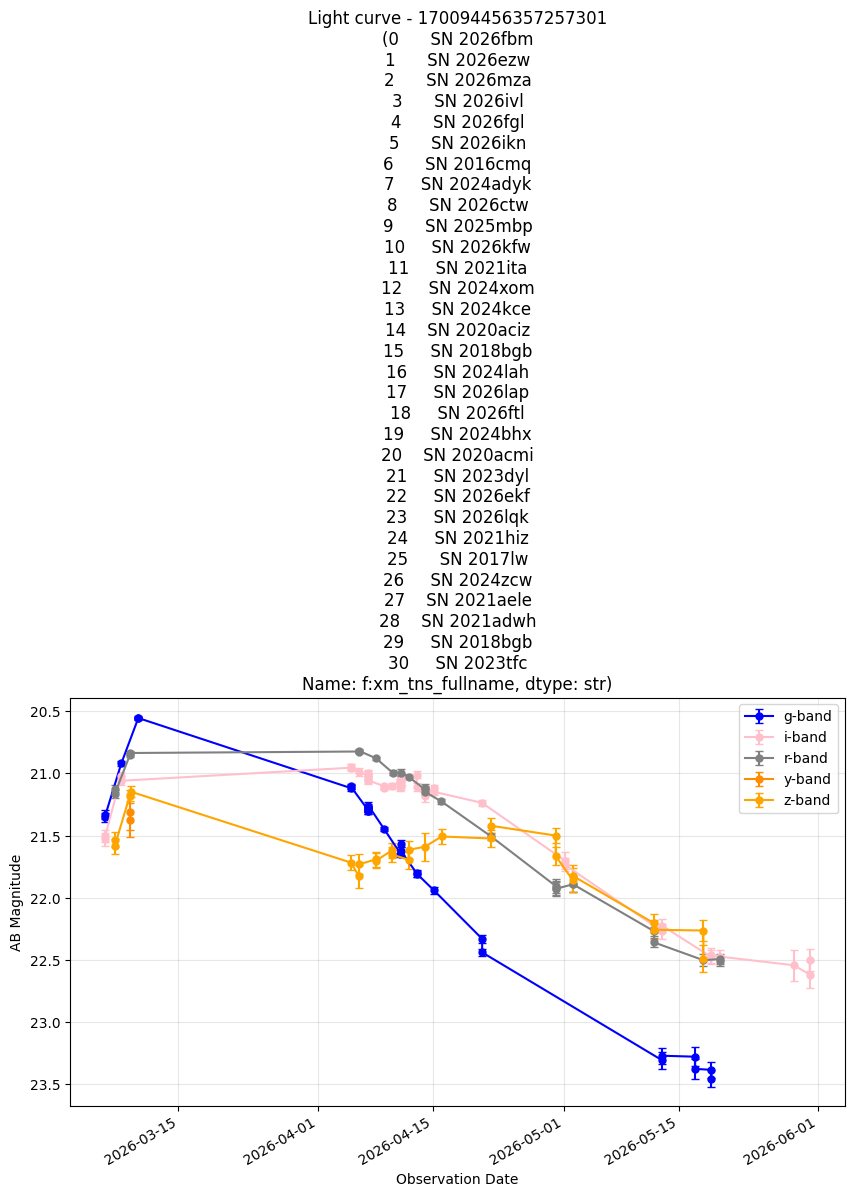

In [ ]:
# in_tns batch light curve plotter
import pandas as pd
import light_curve_plotter as lcp

sn_ia_csv = r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Confirmed_SN\confirmed_SN_tns.csv"
sn_ia_df = pd.read_csv(sn_ia_csv, dtype={"r:diaObjectId": str, "f:xm_tns_fullname": str})
output_directory = r"C:\Users\riley\Documents\University\Honours\Honours_Project\images\SN_Ia_lightcurves"

for sn_ia_object_id in sn_ia_df:
    light_curve_info = lcp.collect_light_curve_data(sn_ia_object_id)
    if light_curve_info == None:
        print (f"{sn_ia_object_id} doesn't have any light curve data avaliable.")
        continue
    if light_curve_info["r:psfFlux"].isna().all():
        print (f"No light curve data avaliable for {sn_ia_object_id}")
        continue
    lcp.lightcurve_plotting(light_curve_info, sn_ia_object_id, output_directory)


In [1]:
# quick length of the rise cuts results to see how many objects passed the cuts and how many didn't.
import pandas as pd
sn_near_galaxy_failed = pd.read_csv(r"/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/sn_near_galaxy_candidates_failed.csv")["r:diaObjectId"]
sn_near_galaxy_passed = pd.read_csv(r"/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/sn_near_galaxy_candidates_passed.csv")["r:diaObjectId"]
extragalactic_failed = pd.read_csv(r"/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/extragalactic_candidates_failed.csv")["r:diaObjectId"]
extragalactic_passed = pd.read_csv(r"/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/extragalactic_candidates_passed.csv")["r:diaObjectId"]

print (f"SN near galaxy candidates that passed the cuts: {len(sn_near_galaxy_passed)}")
print (f"SN near galaxy candidates that failed the cuts: {len(sn_near_galaxy_failed)}")
print (f"Extragalactic candidates that passed the cuts: {len(extragalactic_passed)}")
print (f"Extragalactic candidates that failed the cuts: {len(extragalactic_failed)}")

SN near galaxy candidates that passed the cuts: 1388
SN near galaxy candidates that failed the cuts: 30802
Extragalactic candidates that passed the cuts: 24
Extragalactic candidates that failed the cuts: 307


In [27]:
# Written by Claude Sonnet 4.6 (Anthropic) with the prompt:
# "write a script to sort light curve images into genuine_candidates and false_positives
# subfolders based on a markdown tally file of visual inspection results"

from pathlib import Path

image_dir = Path("/home/riley/Documents/University/Honours/Honours_Project/images/SN_Ia_lightcurves/passed_rate_of_rise_cuts_results")
genuine_dir = image_dir / "Probable_Sn_Ia"
false_positive_dir = image_dir / "False_positives"
genuine_dir.mkdir(exist_ok=True)
false_positive_dir.mkdir(exist_ok=True)

markdown_path = Path("/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/Honours_Project/SN_Ia_Rise_Rate_Cut_Results_Tally.md")

# Parse genuine rising transient IDs from the markdown file
genuine_ids = set()
in_genuine_section = False
with open(markdown_path, "r") as f:
    for line in f:
        line = line.strip()
        if line == "## Genuine Rising transients":
            in_genuine_section = True
            continue
        if line.startswith("##"):
            in_genuine_section = False
        if in_genuine_section and line.startswith("-"):
            # Extract just the ID (first token after the dash, ignore parenthetical notes)
            tokens = line.lstrip("- ").split()
            if not tokens:
                continue
            object_id = tokens[0]
            if not object_id.isdigit():
                continue
            genuine_ids.add(object_id)
            
print(f"Found {len(genuine_ids)} genuine candidate IDs")

moved_genuine = 0
moved_false = 0

for image_path in image_dir.glob("*.png"):
    object_id = image_path.stem
    if object_id in genuine_ids:
        image_path.rename(genuine_dir / image_path.name)
        moved_genuine += 1
    else:
        image_path.rename(false_positive_dir / image_path.name)
        moved_false += 1

print(f"Moved {moved_genuine} images to genuine_candidates/")
print(f"Moved {moved_false} images to false_positives/")

Found 52 genuine candidate IDs
Moved 0 images to genuine_candidates/
Moved 4 images to false_positives/


In [11]:
import pandas as pd
import numpy as np
from pathlib import Path

"""This is the production level script of the rate of rise cuts for the g and r bands of the candidates in sn_near_galaxy_candidate.csv and extragalactic_lt20mag_candidates.csv.
    it will pull object id from the CSV file, fetch the light curve data from the api of the objects,
    apply the 4 minimum detections cut before peak, normalise the fluxes to the current brightest values, 
    compute the linear slope, then apply the 1 sigma cut to the slopes across both bands and then 
    output the candidates that passed and those that didn't into their respective CSV files"""

base_candidate_paths = Path("/home/riley/Documents/University/Honours/Honours_Project/data/extragalactic_object_ids")
in_tns_candidates = list(pd.read_csv(base_candidate_paths / "candidates_in_TNS.csv", dtype={"r:diaObjectId": str})["r:diaObjectId"])

chunk_size = 500
in_tns_candidate_results = []
in_tns_candidates_passed = []
in_tns_candidates_failed = []
red_slope_cut_threshold = 0.0053
green_slope_cut_threshold = 0.0223

# fetch light curve data for each object in the candidate lists with chunking to avoid timeout issues
for diaObjectId in range(0, len(in_tns_candidates), chunk_size):
    in_tns_candidates_light_curve_data = collect_light_curve_data(','.join(in_tns_candidates[diaObjectId:diaObjectId + chunk_size]))
    if in_tns_candidates_light_curve_data is not None:
        in_tns_candidate_results.append(in_tns_candidates_light_curve_data)

if not in_tns_candidate_results:
    raise RuntimeError("No light curve data returned for in_tns candidates")

in_tns_light_curve_info = pd.concat(in_tns_candidate_results, ignore_index=True)

# applying the 4 detections before peak cut and the 1 sigma cut to the slopes in both bands for each candidate
for object_id, group_df in in_tns_light_curve_info.groupby("r:diaObjectId"):
    red_group_df = group_df[group_df["r:band"].isin(["r"])]
    green_group_df = group_df[group_df["r:band"].isin(["g"])]
    if red_group_df.empty or green_group_df.empty:
        in_tns_candidates_failed.append(object_id)
        continue
    red_peak_flux = red_group_df["r:psfFlux"].max()
    green_peak_flux = green_group_df["r:psfFlux"].max()
    peak_red_mjd = red_group_df.loc[red_group_df["r:psfFlux"].idxmax(), "r:midpointMjdTai"]
    peak_green_mjd = green_group_df.loc[green_group_df["r:psfFlux"].idxmax(), "r:midpointMjdTai"]
    pre_peak_red_mjd = red_group_df[red_group_df["r:midpointMjdTai"] < peak_red_mjd]
    pre_peak_green_mjd = green_group_df[green_group_df["r:midpointMjdTai"] < peak_green_mjd]
    if len(pre_peak_red_mjd) >= 4 and len(pre_peak_green_mjd) >= 4:
        red_slope, red_intercept = np.polyfit(pre_peak_red_mjd["r:midpointMjdTai"], (pre_peak_red_mjd["r:psfFlux"]/red_peak_flux), 1)
        green_slope, green_intercept = np.polyfit(pre_peak_green_mjd["r:midpointMjdTai"], (pre_peak_green_mjd["r:psfFlux"]/green_peak_flux), 1)
        if red_slope >= red_slope_cut_threshold and green_slope >= green_slope_cut_threshold:
            # candidate passes the cut
            in_tns_candidates_passed.append(object_id)
        else: 
            in_tns_candidates_failed.append(object_id)
    else:
        in_tns_candidates_failed.append(object_id)

in_tns_candidates_passed_df = pd.DataFrame(in_tns_candidates_passed, columns=["r:diaObjectId"])
in_tns_candidates_passed_df.to_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/in_tns_candidates_passed.csv", index=False)

in_tns_candidates_failed_df = pd.DataFrame(in_tns_candidates_failed, columns=["r:diaObjectId"])
in_tns_candidates_failed_df.to_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/in_tns_candidates_failed.csv", index=False)

# check if the 6 ground truth SN Ia candidates that were in the TNS and had light curves in the Fink database passed the rate of rise cuts. 
ground_truth_sn_object_ids = ["170019717277810735", "170094456400773135", "170094456357257301", "170094456334188639", "170226393328648251", "170235219334922248", "170257199649521669", "170411112000913487"]
in_tns_candidates_passed = list(pd.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/in_tns_candidates_passed.csv", dtype={"r:diaObjectId": str})["r:diaObjectId"])
in_tns_candidates_failed = list(pd.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/in_tns_candidates_failed.csv", dtype={"r:diaObjectId": str})["r:diaObjectId"])

ground_truth_sn_objects_that_passed = []
ground_truth_sn_objects_that_failed = []

for object_id in ground_truth_sn_object_ids:
    if object_id in in_tns_candidates_passed:
        print(f"{object_id} passed the rate of rise cuts")
        ground_truth_sn_objects_that_passed.append(object_id)
    elif object_id in in_tns_candidates_failed:
        print(f"{object_id} failed the rate of rise cuts")
        ground_truth_sn_objects_that_failed.append(object_id)
    else:
        print(f"{object_id} not found in either list")

print (f"Ground truth SN Ia candidates that passed the rate of rise cuts: {ground_truth_sn_objects_that_passed}")
print (f"Ground truth SN Ia candidates that failed the rate of rise cuts: {ground_truth_sn_objects_that_failed}")


170019717277810735 failed the rate of rise cuts
170094456400773135 failed the rate of rise cuts
170094456357257301 failed the rate of rise cuts
170094456334188639 failed the rate of rise cuts
170226393328648251 passed the rate of rise cuts
170235219334922248 passed the rate of rise cuts
170257199649521669 passed the rate of rise cuts
170411112000913487 passed the rate of rise cuts
Ground truth SN Ia candidates that passed the rate of rise cuts: ['170226393328648251', '170235219334922248', '170257199649521669', '170411112000913487']
Ground truth SN Ia candidates that failed the rate of rise cuts: ['170019717277810735', '170094456400773135', '170094456357257301', '170094456334188639']


In [20]:
# quick xcheck of the object IDs that have plots of them and the ones that don't have plots of them to see if any of the objects that passed the rate of rise cuts didn't have plots generated for them.
import pandas as pd
import os
object_ids_passed = pd.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Rate_of_rise_cuts/sn_near_galaxy_candidates_passed.csv", dtype={"r:diaObjectId": str})["r:diaObjectId"].tolist()
object_ids_with_plots_false_positives = ([f.split(".")[0] for f in os.listdir("/home/riley/Documents/University/Honours/Honours_Project/images/SN_Ia_lightcurves/passed_rate_of_rise_cuts_results/False_positives") if f.endswith(".png")])
object_ids_with_plots_probable_SN = ([f.split(".")[0] for f in os.listdir("/home/riley/Documents/University/Honours/Honours_Project/images/SN_Ia_lightcurves/passed_rate_of_rise_cuts_results/Probable_Sn_Ia") if f.endswith(".png")])
object_ids_with_plots = object_ids_with_plots_false_positives + object_ids_with_plots_probable_SN

objects_not_with_plots = []
for object_id in object_ids_passed:
    if object_id not in object_ids_with_plots:
        objects_not_with_plots.append(object_id)
print (f"{(objects_not_with_plots)} passed the rate of rise cuts but doesn't have a plot generated for it.")

['170028485859344404', '170028487249756278', '170028526534656097', '170028526601764952'] passed the rate of rise cuts but doesn't have a plot generated for it.


In [ ]:
# fetching light curve info for the new objects that passed
import light_curve_plotter as lcp

chunk_size = 500
objects_not_with_plots_results =[]
output_path = "/home/riley/Documents/University/Honours/Honours_Project/images/SN_Ia_lightcurves/passed_rate_of_rise_cuts_results"

for diaObjectId in range(0, len(objects_not_with_plots), chunk_size):
    objects_not_with_plots_light_curve_data = lcp.collect_light_curve_data(','.join(objects_not_with_plots[diaObjectId:diaObjectId + chunk_size]))
    if objects_not_with_plots_light_curve_data is not None:
        objects_not_with_plots_results.append(objects_not_with_plots_light_curve_data)

if not objects_not_with_plots_results:
    raise RuntimeError("No light curve data returned for in_tns candidates")

objects_not_with_plots_light_curve_info = pd.concat(objects_not_with_plots_results, ignore_index=True)
objects_not_with_plots_light_curve_info.to_csv("/home/riley/Documents/University/Honours/Honours_Project/images/SN_Ia_lightcurves/passed_rate_of_rise_cuts_results/unplotted_objects.csv", index=False)

In [ ]:
# refactoring the rate of rise and points pre-peak filter into a function
import pandas as pd
import numpy as np
from pathlib import Path
from light_curve_plotter import collect_light_curve_data

"""This is the production level script of the rate of rise cuts for the g and r bands of the candidates in sn_near_galaxy_candidate.csv and extragalactic_lt20mag_candidates.csv.
    it will pull object id from the CSV file, fetch the light curve data from the api of the objects,
    apply the 4 minimum detections cut before peak, normalise the fluxes to the current brightest values, 
    compute the linear slope, then apply the 1 sigma cut to the slopes across both bands and then 
    output the candidates that passed and those that didn't into their respective CSV files"""

base_candidate_paths = Path("/home/riley/Documents/University/Honours/Honours_Project/data/extragalactic_object_ids")
sn_near_galaxy_candidates = list(pd.read_csv(base_candidate_paths / "sn_near_galaxy_candidate.csv", dtype={"r:diaObjectId": str})["r:diaObjectId"])
extragalactic_candidates = list(pd.read_csv(base_candidate_paths / "extragalactic_lt20mag_candidate.csv", dtype={"r:diaObjectId": str})["r:diaObjectId"])
in_tns_candidates = list(pd.read_csv(base_candidate_paths / "candidates_in_TNS", dtype={"r:diaObjectId": str})["r:diaObjectId"])
chunk_size = 500
red_slope_cut_threshold = 0.0053
green_slope_cut_threshold = 0.0223

def applying_rate_of_rise_filter(candidates, chunk_size, red_slope_cut_threshold, green_slope_cut_threshold, output_path_passed, output_path_failed):
    passed, failed = [], []

    candidate_results =[]

    for diaObjectId in range(0, len(candidates), chunk_size):
        candidates_light_curve_data = collect_light_curve_data(','.join(candidates[diaObjectId:diaObjectId + chunk_size]))
        if candidates_light_curve_data is not None:
            candidate_results.append(candidates_light_curve_data)
    
    if not candidate_results:
        raise RuntimeError(f"No light curve data returned for candidate batch of size {len(candidates)}")

    candidate_light_curve_info = pd.concat(candidate_results, ignore_index=True)

    for object_id, group_df in candidate_light_curve_info.groupby("r:diaObjectId"):
        red_group_df = group_df[group_df["r:band"].isin(["r"])]
        green_group_df = group_df[group_df["r:band"].isin(["g"])]
        if red_group_df.empty or green_group_df.empty:
            failed.append(object_id)
            continue
        red_peak_flux = red_group_df["r:psfFlux"].max()
        green_peak_flux = green_group_df["r:psfFlux"].max()
        peak_red_mjd = red_group_df.loc[red_group_df["r:psfFlux"].idxmax(), "r:midpointMjdTai"]
        peak_green_mjd = green_group_df.loc[green_group_df["r:psfFlux"].idxmax(), "r:midpointMjdTai"]
        pre_peak_red_mjd = red_group_df[red_group_df["r:midpointMjdTai"] < peak_red_mjd]
        pre_peak_green_mjd = green_group_df[green_group_df["r:midpointMjdTai"] < peak_green_mjd]
        if len(pre_peak_red_mjd) >= 4 and len(pre_peak_green_mjd) >= 4:
            red_slope, red_intercept = np.polyfit(pre_peak_red_mjd["r:midpointMjdTai"], (pre_peak_red_mjd["r:psfFlux"]/red_peak_flux), 1)
            green_slope, green_intercept = np.polyfit(pre_peak_green_mjd["r:midpointMjdTai"], (pre_peak_green_mjd["r:psfFlux"]/green_peak_flux), 1)
            if red_slope >= red_slope_cut_threshold and green_slope >= green_slope_cut_threshold:
                # candidate passes the cut
                passed.append(object_id)
            else: 
                failed.append(object_id)
        else:
            failed.append(object_id)

    # writing the passed candidates to their respective CSV files
    passed_df = pd.DataFrame(passed, columns=["r:diaObjectId"])
    passed_df.to_csv(output_path_passed, index=False)
    failed_df = pd.DataFrame(failed, columns=["r:diaObjectId"])
    failed_df.to_csv(output_path_failed, index=False)

    return passed, failed

In [ ]:
#r and g band rise rates draft script

# finding the rate of rise in the r band of the in_tns SN candidates so that we have an empirical value to build the filter around
from light_curve_plotter import collect_light_curve_data, lightcurve_plotting
import pandas as pd
import numpy as np

tns_fullname = ["SN 2026ezw", "SN 2026fbm", "SN 2026ikn", "SN 2026ivl", "SN 2026kfw", "SN 2026mza"]
df = pd.read_csv(r"/home/riley/Documents/University/Honours/Honours_Project/data/Confirmed_SN/confirmed_SN_tns.csv")
df = df[df["f:xm_tns_fullname"].isin(tns_fullname)]
object_ids = (df["r:diaObjectId"].tolist())
object_ids = list(map(str, object_ids))
object_ids = ','.join(object_ids)

red_band = ["r"]
green_band =["g"]

green_slopes = []
red_slopes = []
red_counts_per_object = []
green_counts_per_object = []
green_std_devs = []
red_std_devs = []

light_curve_info = collect_light_curve_data(object_ids)
for object_id, group_df in light_curve_info.groupby("r:diaObjectId"):
    red_group_df = group_df[group_df["r:band"].isin(red_band)]
    green_group_df = group_df[group_df["r:band"].isin(green_band)]
    red_peak_flux = red_group_df["r:psfFlux"].max()
    green_peak_flux = green_group_df["r:psfFlux"].max()
    peak_red_mjd = red_group_df.loc[red_group_df["r:psfFlux"].idxmax(), "r:midpointMjdTai"]
    peak_green_mjd = green_group_df.loc[green_group_df["r:psfFlux"].idxmax(), "r:midpointMjdTai"]
    pre_peak_red_mjd = red_group_df[red_group_df["r:midpointMjdTai"] < peak_red_mjd]
    pre_peak_green_mjd = green_group_df[green_group_df["r:midpointMjdTai"] < peak_green_mjd]
    red_counts_per_object.append(len(pre_peak_red_mjd))
    green_counts_per_object.append(len(pre_peak_green_mjd))
    red_slope, red_intercept = np.polyfit(pre_peak_red_mjd["r:midpointMjdTai"], (pre_peak_red_mjd["r:psfFlux"]/red_peak_flux), 1)
    green_slope, green_intercept = np.polyfit(pre_peak_green_mjd["r:midpointMjdTai"], (pre_peak_green_mjd["r:psfFlux"]/green_peak_flux), 1)
    green_slopes.append(green_slope)
    red_slopes.append(red_slope)
    green_std_dev = np.std(pre_peak_green_mjd["r:psfFlux"]/green_peak_flux)
    red_std_dev = np.std(pre_peak_red_mjd["r:psfFlux"]/red_peak_flux)
    green_std_devs.append(green_std_dev)
    red_std_devs.append(red_std_dev)
    green_std_devs.append(green_std_dev)
    red_std_devs.append(red_std_dev)

# print (f"Average counts - Red: {np.average(red_counts_per_object):.4f}, Green: {np.average(green_counts_per_object):.4f}")
# print (f"Average slopes - Red: {np.average(red_slopes):.4f}, Green: {np.average(green_slopes):.4f}")
# print (f"Average standard deviations - Red: {np.average(red_std_devs):.4f}, Green: {np.average(green_std_devs):.4f}")
print (f"These are the slopes in the green band before peak\n{sorted(green_slopes)}")
print (f"These are the slopes in the red band before peak\n{sorted(red_slopes)}")

In [ ]:
# draft for a batch light curve plotter that was intially tested on tns data only
# Batch plotter for the labelled in_tns objects. This was done so that I can understand what the light curves of a SN Ia looks like. Builds a validation dataset.
import pandas as pd
from pathlib import Path
from light_curve_plotter import lightcurve_plotting
from light_curve_plotter import collect_light_curve_data

output_path = Path(r"/home/riley/Documents/University/Honours/Honours_Project/images/SN_Ia_lightcurves/in_tns")

in_tns_object_ids = list((pd.read_csv(r"/home/riley/Documents/University/Honours/Honours_Project/data/Confirmed_SN/confirmed_SN_tns.csv", dtype= {"r:diaObjectId": str}))["r:diaObjectId"])
in_tns_object_names = list((pd.read_csv(r"/home/riley/Documents/University/Honours/Honours_Project/data/Confirmed_SN/confirmed_SN_tns.csv", dtype= {"f:xm_tns_fullname": str}))["f:xm_tns_fullname"])
tns_lookup = dict(zip(in_tns_object_ids, in_tns_object_names))
in_tns_object_ids = ",".join(in_tns_object_ids)

# need lightcurve data first retrived from the strings of diaobject ID from the csv files. 
light_curve_info = collect_light_curve_data(in_tns_object_ids)
for object_id, group_df in light_curve_info.groupby("r:diaObjectId"):
    object_id = str(object_id)
    # lightcurve_plotting takes a df, diaObjectId and a source file string as arguments
    lightcurve_plotting(group_df, object_id, tns_lookup[object_id], output_path / f"{tns_lookup[object_id]}")

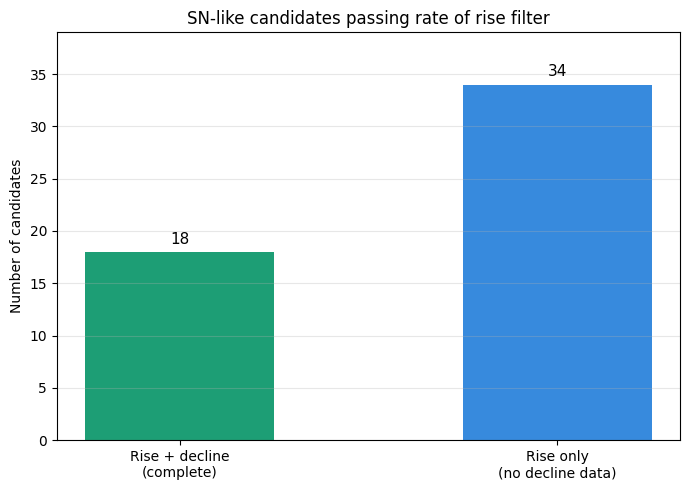

In [1]:
# Written by Claude Sonnet 4.6 (Anthropic) with the prompt:
# "Alright, I have 18 SN shaped curves that passed the rate of rise filter that have a
# decline and 34 that passed and have an SN-like rise that is notable but lack decline
# data. Could you make the histogram for me please using matplotlib.pyplot."

import matplotlib.pyplot as plt

categories = ["Rise + decline\n(complete)", "Rise only\n(no decline data)"]
counts = [18, 34]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(categories, counts, color=["#1D9E75", "#378ADD"], width=0.5)

for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            str(count), ha="center", va="bottom", fontsize=11)

ax.set_ylabel("Number of candidates")
ax.set_title("SN-like candidates passing rate of rise filter")
ax.set_ylim(0, max(counts) + 5)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("/home/riley/Documents/University/Honours/Honours_Project/images/fink_stand_up_meetings/rate_of_rise_candidates_histogram.png", dpi=150)
plt.show()

In [ ]:
"""Removing duplicates in the images rate of rise passed directory of objects that have had their light curves already sorted in the sub directories."""

from pathlib import Path
import requests  

honours_root = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project"
lightcurve_root = honours_root / "images" / "SN_lightcurves" / "passed_rate_of_rise_cuts_results"

image_dir = lightcurve_root
sorted_dirs = [
    lightcurve_root / "anomalies",
    lightcurve_root / "declining_objects",
    lightcurve_root / "flat_curves_with_noise",
    lightcurve_root / "genuine_candidates",
    lightcurve_root / "single_band_detections"  
]

def stems(directory: Path, suffix: str = "*.png") -> set[str]:
    if not directory.exists():
        print(f"Missing: {directory}")
        return set()
    return {p.stem for p in directory.glob(suffix)}

new_image_stems = stems(image_dir)

already_sorted_stems = set()
for d in sorted_dirs:
    already_sorted_stems |= stems(d)

duplicates = new_image_stems & already_sorted_stems
unsorted = new_image_stems - already_sorted_stems

print(f"{len(duplicates)} duplicates already sorted")
print(f"{len(unsorted)} still unsorted")

for p in image_dir.glob("*.png"):
    if p.stem in duplicates:
        p.unlink()
        print(f"Removed duplicate: {p.name}")

47 duplicates already sorted
0 still unsorted
Removed duplicate: 170019696475111620.png
Removed duplicate: 170019716456251517.png
Removed duplicate: 170028485792759925.png
Removed duplicate: 170028485795381395.png
Removed duplicate: 170028486112051263.png
Removed duplicate: 170028486213238822.png
Removed duplicate: 170028486602784874.png
Removed duplicate: 170028486662029429.png
Removed duplicate: 170028488800075841.png
Removed duplicate: 170028489219506248.png
Removed duplicate: 170028511293079565.png
Removed duplicate: 170028511473959008.png
Removed duplicate: 170028513065697415.png
Removed duplicate: 170028516801249350.png
Removed duplicate: 170028526517354569.png
Removed duplicate: 170028526583414787.png
Removed duplicate: 170028526852374631.png
Removed duplicate: 170028527181627479.png
Removed duplicate: 170028527291203638.png
Removed duplicate: 170028527681798164.png
Removed duplicate: 170028528277913675.png
Removed duplicate: 170028528481337369.png
Removed duplicate: 17002852848

In [10]:
"""Script to make the CSV file that objects go into after they have been visually inspected"""
import pandas as pd
import os
from pathlib import Path

# Dir where all the plots of the lightcurves go.
PLOT_RESULTS_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "images" / "SN_lightcurves" / "passed_rate_of_rise_cuts_results"

# Sub-directories where the object plots are stored 
SUBDIRECTORIES = [PLOT_RESULTS_DIR / "anomalies", 
                PLOT_RESULTS_DIR / "declining_objects",
                PLOT_RESULTS_DIR / "flat_curves_with_noise",
                PLOT_RESULTS_DIR / "genuine_candidates",
                PLOT_RESULTS_DIR / "single_band_detections"]

OUTPUT_PATH = Path.home() /"Documents"/"University"/"Honours"/"Honours_Project"/"data"/"visual_inspection"

# The format of the CSV file and the data that the objects will be appended to.
DATA = {
    'diaObjectId' : [],
    'Category' : [],
    'Notes' : []
}

for directory in SUBDIRECTORIES:
    for file in directory.iterdir():
        DATA["diaObjectId"].append(file.stem)
        DATA["Category"].append(directory.stem)
        DATA["Notes"].append("(Fill from Joplin Note)")

df = pd.DataFrame(DATA)
df.to_csv(OUTPUT_PATH / "visual_inspection_results.csv", columns=["diaObjectId", "Category", "Notes"], index=False)

In [17]:
"""
This script cross-checks the visual inspection CSV against the current location of
each object's light curve plot, and moves any plot that isn't already sitting in the
directory matching its assigned category.
"""

import pandas as pd
from pathlib import Path

# Define directories
PLOT_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "images" / "SN_lightcurves"
IMAGE_DIR = PLOT_DIR / "passed_rate_of_rise_cuts_results"
GENUINE_DIR = IMAGE_DIR / "genuine_candidates"
FLAT_CURVE_DIR = IMAGE_DIR / "flat_curves_with_noise"
DECLINING_DIR = IMAGE_DIR / "declining_objects"
SINGLE_BAND_DIR = IMAGE_DIR / "single_band_detections"
ANOMALY_DIR = IMAGE_DIR / "anomalies"

# Visual inspection result directory
CSV_RESULTS_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "data" / "visual_inspection" / "visual_inspection_results.csv"
csv_object_df = pd.read_csv(CSV_RESULTS_DIR, dtype={"diaObjectId": str})

constructed_dirs = {
    'anomalies': [],
    'declining_objects': [],
    'flat_curves_with_noise': [],
    'genuine_candidates': [],
    'single_band_detections': []
}

# Building a lookup of every existing plot's stem (diaObjectId) -> its current Path,
# searched once across the whole results tree rather than per-object.
object_id_lookup = {image.stem: image for image in PLOT_DIR.rglob("*.png")}

# Pair each object's diaObjectId with its expected path, grouped by category
for index, row in csv_object_df.iterrows():
    if row["Category"] in constructed_dirs:
        expected_path = IMAGE_DIR / row["Category"] / (row["diaObjectId"] + ".png")
        constructed_dirs[row["Category"]].append((row["diaObjectId"], expected_path))

# Check each expected path; if the plot isn't already there, find it via the lookup and move it
moved = 0
missing = 0

for category, entries in constructed_dirs.items():
    for object_id, expected_path in entries:
        if expected_path.exists():
            continue

        current_path = object_id_lookup.get(object_id)
        if current_path is None:
            print(f"No plot found on disk for {object_id} (expected category: {category})")
            missing += 1
            continue

        expected_path.parent.mkdir(parents=True, exist_ok=True)
        current_path.rename(expected_path)
        moved += 1
        print(f"Moved {object_id}: {current_path} -> {expected_path}")

print(f"\nDone. Moved {moved} plots, {missing} objects had no plot found on disk.")

Moved 313756671726845988: /home/riley/Documents/University/Honours/Honours_Project/images/SN_lightcurves/313756671726845988.png -> /home/riley/Documents/University/Honours/Honours_Project/images/SN_lightcurves/passed_rate_of_rise_cuts_results/anomalies/313756671726845988.png

Done. Moved 1 plots, 0 objects had no plot found on disk.


In [ ]:
"""
This script cross-checks the visual inspection CSV against the current location of
each object's light curve plot, and moves any plot that isn't already sitting in the
directory matching its assigned category.
"""

# Written by Claude Sonnet 4.6 (Anthropic) with the prompt:
# "Here is what I have so far as a draft and I am kind of stuck with how to find the
# file that currently has that object ID... [draft script pasted]... could you make
# the edits and I will supervise please?" followed by "Now can you refactor it so
# each different step is its own function please?"

import pandas as pd
from pathlib import Path

# Define directories
PLOT_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "images" / "SN_lightcurves"
IMAGE_DIR = PLOT_DIR / "passed_rate_of_rise_cuts_results"
GENUINE_DIR = IMAGE_DIR / "genuine_candidates"
FLAT_CURVE_DIR = IMAGE_DIR / "flat_curves_with_noise"
DECLINING_DIR = IMAGE_DIR / "declining_objects"
SINGLE_BAND_DIR = IMAGE_DIR / "single_band_detections"
ANOMALY_DIR = IMAGE_DIR / "anomalies"

CSV_RESULTS_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "data" / "visual_inspection" / "visual_inspection_results.csv"

CATEGORIES = [
    'anomalies',
    'declining_objects',
    'flat_curves_with_noise',
    'genuine_candidates',
    'single_band_detections'
]


def build_object_id_lookup(image_dir: Path) -> dict[str, Path]:
    """
    Searches recursively across image_dir for every .png file and builds a
    lookup of diaObjectId (the file stem) -> its current Path.

    This is done once upfront so that finding an object's current location is a
    single dict lookup rather than a fresh filesystem search per object.
    """
    return {image.stem: image for image in image_dir.rglob("*.png")}


def build_expected_paths(csv_object_df: pd.DataFrame, image_dir: Path, categories: list[str]) -> dict[str, list[tuple[str, Path]]]:
    """
    Groups (diaObjectId, expected_path) pairs by category, based on the
    visual inspection CSV. expected_path is where that object's plot should
    live if it has already been sorted correctly.
    """
    constructed_dirs = {category: [] for category in categories}

    for _, row in csv_object_df.iterrows():
        if row["Category"] in constructed_dirs:
            expected_path = image_dir / row["Category"] / (row["diaObjectId"] + ".png")
            constructed_dirs[row["Category"]].append((row["diaObjectId"], expected_path))

    return constructed_dirs


def move_misplaced_plots(constructed_dirs: dict[str, list[tuple[str, Path]]], object_id_lookup: dict[str, Path]) -> tuple[int, int]:
    """
    For each expected (diaObjectId, expected_path) pair, checks whether the
    plot is already at expected_path. If not, looks up its current location
    and moves it there. Returns (moved_count, missing_count).
    """
    moved = 0
    missing = 0

    for category, entries in constructed_dirs.items():
        for object_id, expected_path in entries:
            if expected_path.exists():
                continue

            current_path = object_id_lookup.get(object_id)
            if current_path is None:
                print(f"No plot found on disk for {object_id} (expected category: {category})")
                missing += 1
                continue

            expected_path.parent.mkdir(parents=True, exist_ok=True)
            current_path.rename(expected_path)
            moved += 1
            print(f"Moved {object_id}: {current_path} -> {expected_path}")

    return moved, missing


def sort_plots_from_csv(csv_path: Path, image_dir: Path, categories: list[str]) -> None:
    """
    Orchestrates the full sorting process: reads the visual inspection CSV,
    builds the current-location lookup, works out where each plot should be,
    and moves any plots that are in the wrong place.
    """
    csv_object_df = pd.read_csv(csv_path, dtype={"diaObjectId": str})

    object_id_lookup = build_object_id_lookup(image_dir)
    constructed_dirs = build_expected_paths(csv_object_df, image_dir, categories)
    moved, missing = move_misplaced_plots(constructed_dirs, object_id_lookup)

    print(f"\nDone. Moved {moved} plots, {missing} objects had no plot found on disk.")


if __name__ == "__main__":
    sort_plots_from_csv(CSV_RESULTS_DIR, IMAGE_DIR, CATEGORIES)

In [ ]:
"""This script was used for the plotting a random sample of the objects that didn't pass the rate of rise cut.

This is useful so we can see if the rate of rise cut is effectivly cutting flat objects from the tag filtering or if it
is cutting out some genuine rising transients. Which tells us that the current cut threshold is too strict. """

import generic_light_curve_batch_plotter as glcbp
from pathlib import Path
import pandas as pd
import random 

CANDIDATES_BASE_PATH = Path.home() / "Documents"/ "University" / "Honours" / "Honours_Project" / "data" / "Rate_of_rise_cuts"

ID_DICT = {"sn_near_galaxy_failed" : [],
        "in_tns_failed" : [],
        "extragalactic_lt20mag_failed" : []}

sn_near_galaxy_candidates_failed_ids = pd.read_csv(CANDIDATES_BASE_PATH / "sn_near_galaxy_candidates_failed.csv", dtype={"r:diaObjectId":str})["r:diaObjectId"].tolist()
extragalactic_candidates_failed_ids = pd.read_csv(CANDIDATES_BASE_PATH / "extragalactic_candidates_failed.csv", dtype={"r:diaObjectId":str})["r:diaObjectId"].tolist()
in_tns_candidates_failed_ids = pd.read_csv(CANDIDATES_BASE_PATH / "in_tns_candidates_failed.csv", dtype={"r:diaObjectId":str})["r:diaObjectId"].tolist()

for ids in sn_near_galaxy_candidates_failed_ids:
    ID_DICT["sn_near_galaxy_failed"].append(ids)
for ids in extragalactic_candidates_failed_ids:
    ID_DICT["extragalactic_lt20mag_failed"].append(ids)
for ids in in_tns_candidates_failed_ids:
    ID_DICT["in_tns_failed"].append(ids)

# for key, value in ID_DICT.items():
#     sample_size = min(1000, len(value))
#     sample_ids = random.sample(value, sample_size)
#     output_dir = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "images" / "SN_lightcurves" / "failed_rate_of_rise_cuts_results" / key
#     output_dir.mkdir(parents=True, exist_ok=True)
#     glcbp.batch_plotter(sample_ids, 500, output_dir)

KeyboardInterrupt: 

In [12]:
"""Script to make all plots that didn't get a category label to be labeled 'flat_curve_with_noise'"""
from pathlib import Path
import pandas as pd 

FAILED_VISUAL_INSPECTION_RESULTS_PATH = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "data" / "visual_inspection" / "failed_visual_inspection_results.csv"

PLOT_DIRS = {
    "sn_near_galaxy_failed": Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "images" / "SN_lightcurves" / "failed_rate_of_rise_cuts_results" / "sn_near_galaxy_failed",
    "extragalactic_lt20mag_failed": Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "images" / "SN_lightcurves" / "failed_rate_of_rise_cuts_results" / "extragalactic_lt20mag_failed",
    "in_tns_failed": Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "images" / "SN_lightcurves" / "failed_rate_of_rise_cuts_results" / "in_tns_failed",
}

ID_DICT = {
    key: [f.stem for f in plot_dir.glob("*.png")]
    for key, plot_dir in PLOT_DIRS.items()

}
failed_visual_inspection_results = pd.read_csv(FAILED_VISUAL_INSPECTION_RESULTS_PATH, dtype={"diaObjectId":str})["diaObjectId"].tolist()

new_flat_curve_with_noise_entries = []

for key, value in ID_DICT.items():
    for objectid in value:
        if objectid not in failed_visual_inspection_results:
            new_flat_curve_with_noise_entries.append({"diaObjectId": objectid, "Category": "flat_curves_with_noise", "Notes": ""})

new_entries_df = pd.DataFrame(new_flat_curve_with_noise_entries)
new_entries_df.to_csv(FAILED_VISUAL_INSPECTION_RESULTS_PATH, mode="a", header=False, index=False)

In [5]:
# plots the light curve of the objects that haven't pass through all three classifiers that we run.
import io
import requests as re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time

band_colours = {"u": "darkblue", "g":"blue", "r": "red", "i":"darkred", "z":"orange", "y":"black"}   

def collect_light_curve_data(diaObjectId):
    r = re.post(
        "https://api.lsst.fink-portal.org/api/v1/sources",
        json={
            "diaObjectId": diaObjectId,
            "columns": "r:diaObjectId, r:diaSourceId,r:midpointMjdTai,r:psfFlux,r:psfFluxErr, r:band",
            "output-format": "json",
        },
    )
    if r.status_code != 200:
        print (f"Failed to fetch the light curve info for {diaObjectId}: {r.status_code}")
        return None
    return pd.read_json(io.BytesIO(r.content))

def flux_to_mag(flux, flux_err):
    """Converting nanojansky flux to AB magnitude with uncertainties"""
    AB_mag = -2.5*np.log10(flux) + 31.4
    AB_mag_err = (2.5 / np.log(10)) * (flux_err / flux)
    return AB_mag, AB_mag_err

def lightcurve_plotting(df: pd.DataFrame, diaObjectId: str, source_file: str, output_dir: str):
    df = df[df["r:psfFlux"] > 0].copy()
    df = df.sort_values("r:midpointMjdTai")
    df["mag"], df["mag_err"] = flux_to_mag(df["r:psfFlux"], df["r:psfFluxErr"])
    df["date"] = Time(df["r:midpointMjdTai"].values, format="mjd").to_datetime()

    fig, ax = plt.subplots(figsize = (10, 6))

    for band, group in df.groupby("r:band"):
        colour = band_colours.get(band, "black")
        ax.errorbar(
            group["date"],
            group["mag"],
            yerr = group["mag_err"],
            fmt = "o",
            color = colour,
            label = f"{band}-band",
            capsize = 3,
            markersize = 5)
        
    ax.invert_yaxis()
    ax.set_xlabel("Observation Date")
    ax.set_ylabel("AB magnitude")
    ax.set_title(f"Light curve - {diaObjectId}\n({source_file})")
    ax.legend()
    ax.grid(True, alpha = 0.3)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.savefig(output_dir)
    plt.close(fig)

In [7]:
"""Plotting an object with different colour points for a Fink standup"""

# Defining object to be plotted
object_id = "313853497291309068"

light_curve_info = collect_light_curve_data(object_id)
print (light_curve_info)

# lightcurve_plotting(light_curve_info, object_id, object_id, r"C:\Users\riley\Pictures")


Failed to fetch the light curve info for 313853497291309068: 504
None


In [ ]:
"""Randomly sampling 1000 test objects from SN_near_galaxy_tag and then running the results through the slope fitting filter."""
import polars as pl
from pathlib import Path

# Directories
SN_NEAR_GALAXY_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "data" / "extragalactic_object_ids" / "sn_near_galaxy_candidate.csv"
RANDOM_SAMPLE_OUTPUT_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "data" / "test_data" / "1000_random_test_objects.csv"

# Reading the CSV required for passing the data
SN_NEAR_GALAXY_CANDIDATES = pl.read_csv(SN_NEAR_GALAXY_DIR)

# Random sampling of the SN near galaxy candidates
(SN_NEAR_GALAXY_CANDIDATES.sample(1000, seed=42)).write_csv(RANDOM_SAMPLE_OUTPUT_DIR)

In [18]:
import pandas as pd

def collect_light_curve_info_with_fallback(candidates: list[str]) -> pd.DataFrame | None:
    """This function collects the lightcurve info of an object
    and factors in a recursive self repair incase the script timesout
    while running on large requests."""

    data = collect_light_curve_data(",".join(candidates))
    if data is not None:
        return data

    if len(candidates) <= 1:
        print(f"Could not fetch data for object {candidates}, skipping.")
        return None

    mid = len(candidates) // 2
    left = collect_light_curve_info_with_fallback(candidates[:mid])
    right = collect_light_curve_info_with_fallback(candidates[mid:])

    candidates_parts = [df for df in (left, right) if df is not None]
    if not candidates_parts:
        return None
    return pd.concat(candidates_parts)


def chunked_light_curve_data(candidates: list, chunk_size: int = 500) -> pd.DataFrame:
    """
    This function scrapes the Fink API for the light curve info necessary
    to make cuts based on object qualities and produce plots of the light curves.
    """
    candidate_results = []

    for diaObjectId in range(0, len(candidates), chunk_size):
        chunked_ids = candidates[diaObjectId:diaObjectId + chunk_size]
        candidates_light_curve_data = collect_light_curve_info_with_fallback(chunked_ids)
        if candidates_light_curve_data is not None:
            candidate_results.append(candidates_light_curve_data)

    if not candidate_results:
        raise RuntimeError(f"No light curve data returned for candidate batch of size {len(candidates)}")

    return pd.concat(candidate_results, ignore_index=True)

In [16]:
"""Collecting and storing light curve data for local access when Fink is shutdown for August."""
import polars as pl

def chunked_light_curve_data(candidates: list, chunk_size: int = 500) -> pl.DataFrame:
    """
    This function scrapes the Fink API for the light curve info necessary
    to make cuts based on object qualities and produce plots of the light curves.
    """
    candidate_results = []

    for diaObjectId in range(0, len(candidates), chunk_size):
        chunked_ids = candidates[diaObjectId:diaObjectId + chunk_size]
        candidates_light_curve_data = collect_light_curve_info_with_fallback(chunked_ids)
        
        if candidates_light_curve_data is not None and not candidates_light_curve_data.empty:
            # Convert Pandas DataFrame to Polars DataFrame
            pl_df = pl.from_pandas(candidates_light_curve_data)
            candidate_results.append(pl_df)

    if not candidate_results:
        raise RuntimeError(f"No light curve data returned for candidate batch of size {len(candidates)}")

    return pl.concat(candidate_results)

objects = pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/extragalactic_object_ids/extragalactic_lt20mag_candidate.csv", schema_overrides={"r:diaObjectId": pl.String}, columns=["r:diaObjectId"])["r:diaObjectId"].to_list()

light_curve_data = chunked_light_curve_data(objects, 500)

light_curve_data.write_parquet("/home/riley/Documents/University/Honours/Honours_Project/data/light_curve_data/extragalactic_lt20mag_candidate_light_curve_info.parquet")

KeyboardInterrupt: 

In [3]:
"""De-dupeing the confirmed rise csv"""
import polars as pl

confirmed_rises_ids = pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Confirmed_SN/confirmed_rises.csv")
print (confirmed_rises_ids)
deduped_confirmed_rises_ids = confirmed_rises_ids.unique(keep="first")
deduped_confirmed_rises_ids.write_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Confirmed_SN/confirmed_rises.csv")
print (deduped_confirmed_rises_ids)

shape: (259, 1)
┌────────────────────┐
│ r:diaObjectId      │
│ ---                │
│ i64                │
╞════════════════════╡
│ 170019716323082348 │
│ 170032900274651160 │
│ 170032917163016282 │
│ 170046089928376424 │
│ 170235219334922248 │
│ …                  │
│ 313967752817672227 │
│ 313980945119576112 │
│ 313985346353234012 │
│ 313998569640558678 │
│ 314003014107006318 │
└────────────────────┘
shape: (171, 1)
┌────────────────────┐
│ r:diaObjectId      │
│ ---                │
│ i64                │
╞════════════════════╡
│ 313699505018503202 │
│ 313695087470575667 │
│ 313831458355544118 │
│ 170274770629689377 │
│ 170274770656952330 │
│ …                  │
│ 313879818504503352 │
│ 313928194477522960 │
│ 170226393351716950 │
│ 313853497291309068 │
│ 313950161050533922 │
└────────────────────┘


In [2]:
"""Acquiring the CATS and SNN ML classifier scores for those 171 objects."""
import requests as re
import pandas as pd
import io
from pathlib import Path

# Pulling from the sources api to get the classifier scores for the ObjectIds Obtained from data_ingestion
api_url_sources = "https://api.lsst.fink-portal.org/api/v1/sources"

# Input directory path
RISING_OBJECTS = Path.home() /"Documents"/"University"/"Honours"/"Honours_Project"/"data"/"Confirmed_SN"/"confirmed_rises.csv"

# Output directory path
OUTPUT_DIR = Path.home() /"Documents"/"University"/"Honours"/"Honours_Project"/"data"/"extragalactic_object_classified"/"confirmed_rises_classified.csv"

def collect_classifier_scores_batch(object_ids: list) -> pd.DataFrame | None:
    """Collects classifier scores for all the filtered object ids"""
    
    r0 = re.post(api_url_sources,
        json={
            "diaObjectId": object_ids,
            "columns": "r:diaObjectId, f:clf_cats_class, f:clf_cats_score, f:clf_earlySNIa_score, f:clf_snnSnVsOthers_score",
            "output-format": "json"
        })
    
    if r0.status_code != 200:
        print(f"Batch request failed: {r0.status_code}")
        return None
    
    return pd.read_json(io.BytesIO(r0.content))

def classification_concatenation(csv_file: list[Path], output_path: list[Path]):
    # for csv_file, output_path in zip(csv_files, output_paths):
    #     print(f"\nProcessing objects from {csv_file}")
    object_ids = pd.read_csv(csv_file, dtype={"r:diaObjectId" : str})["r:diaObjectId"].tolist()

    chunk_size = 500
    combined = []
    for diaObjectId in range(0, len(object_ids), chunk_size):
        object_classifier_scores = collect_classifier_scores_batch(",".join(object_ids[diaObjectId:diaObjectId + chunk_size]))
        if object_classifier_scores is not None:
            combined.append(object_classifier_scores)
    if not combined:
        raise RuntimeError(f"No classifier scores returned for {csv_file}")
    
    combined = pd.concat(combined, ignore_index=True)

    combined_agg = combined.groupby("r:diaObjectId").agg(
        clf_cats_class_mode  = ("f:clf_cats_class",             lambda x: x.mode()[0]),
        clf_cats_score_max   = ("f:clf_cats_score",             lambda x: x[x >= 0].max()),
        clf_cats_score_mean  = ("f:clf_cats_score",             lambda x: x[x >= 0].mean()),
        clf_earlySNIa_max    = ("f:clf_earlySNIa_score",        lambda x: x[x >= 0].max()),
        clf_earlySNIa_mean   = ("f:clf_earlySNIa_score",        lambda x: x[x >= 0].mean()),
        clf_snn_max          = ("f:clf_snnSnVsOthers_score",    lambda x: x[x >= 0].max()),
        clf_snn_mean         = ("f:clf_snnSnVsOthers_score",    lambda x: x[x >= 0].mean()),
        n_detections         = ("r:diaObjectId",                "count"),
    ).reset_index()

    combined_agg.to_csv(output_path, index=False)
    print(f"Saved {len(combined_agg)} objects to {output_path}")


classification_concatenation(RISING_OBJECTS, OUTPUT_DIR)

Saved 171 objects to /home/riley/Documents/University/Honours/Honours_Project/data/extragalactic_object_classified/confirmed_rises_classified.csv


In [8]:
"""Finding what objects have SNN >= 0.7, CATS Class == 11 and CATS score >=0.9"""
from pathlib import Path
import polars as pl

# Reading the Objects with classification scores.
CONFIRMED_RISES_IDS_CLASSIFIED = pl.read_csv(Path.home() /"Documents"/"University"/"Honours"/"Honours_Project"/"data"/"extragalactic_object_classified"/"confirmed_rises_classified.csv")

# Filtering the confirmed rises classified IDS
filtered_df = CONFIRMED_RISES_IDS_CLASSIFIED.filter((pl.col("clf_cats_class_mode") == 11) & (pl.col("clf_cats_score_mean") >= 0.9) & (pl.col("clf_snn_mean") >= 0.7))
filtered_df.write_csv("/home/riley/Documents/University/Honours/Honours_Project/data/Potential_SN_candidates/confirmed_rises_ml_cuts_results.csv")

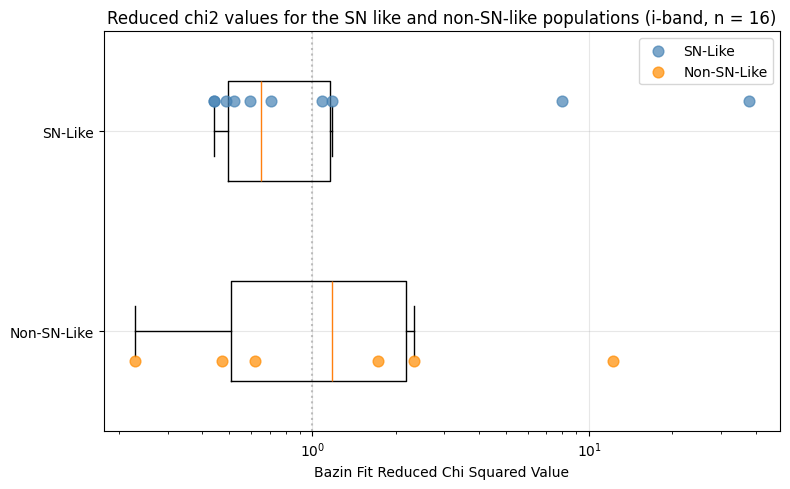

In [14]:
"""Distribution of the chi squared for the 20 objects both bad objects and good objects to test how effectivly the model fits to the diferrent data."""
import matplotlib.pyplot as plt
from pathlib import Path
import polars as pl

# 20 object test directory path
TWENTY_OBJECT_TEST_DIR = Path.home() / "Documents" / "University" / "Honours" / "Honours_Project" / "data" / "bazin_fits" / "20_object_test"

# Read the CSV and extract jsut the chi squared values
CHI_SQUARED_VALUES = pl.read_csv(TWENTY_OBJECT_TEST_DIR / "bazin_fits_i_band_results.csv", schema_overrides={"reduced_chi2":pl.Float64}, columns=["reduced_chi2"])["reduced_chi2"].to_list()

fig, axes = plt.subplots(figsize = (8,5))

sn_chi2 = CHI_SQUARED_VALUES[:10]
non_sn_chi2 = CHI_SQUARED_VALUES[10:20]

axes.boxplot([non_sn_chi2, sn_chi2], positions=[0, 1], vert=False, widths=0.5, showfliers=False)
axes.scatter(sn_chi2, [1.15] * len(sn_chi2), color="steelblue", alpha=0.7, s=60, label="SN-Like", zorder=3)
axes.scatter(non_sn_chi2, [-0.15] * len(non_sn_chi2), color="darkorange", alpha=0.7, s=60, label="Non-SN-Like", zorder=3)

axes.set_yticks([0, 1])
axes.set_yticklabels(["Non-SN-Like", "SN-Like"])
axes.axvline(1, color="gray", linestyle=":", alpha= 0.5, zorder = 1)
axes.legend()

axes.set_xscale("log")
axes.set_xlabel("Bazin Fit Reduced Chi Squared Value")
axes.set_title("Reduced chi2 values for the SN like and non-SN-like populations (i-band, n = 16)")
axes.grid(alpha = 0.3)
plt.tight_layout()
plt.savefig("/home/riley/Documents/University/Honours/Honours_Project/images/bazin_fits/20_object_test/chi_squared_distribution_r_band.png")

In [2]:
"""Easy X match to check if objects that passed/failed are SN/non SN """
import polars as pl
from pathlib import Path

# The directories for the objects that passed and the objects that failed.
TEST_DATA_DIR = Path.home() / "Documents" / "University"/"Honours"/"Honours_Project"/"data"/"test_data"
PASSED_OBJECTS =  TEST_DATA_DIR / "test_passed.csv"
FAILED_OBJECTS = TEST_DATA_DIR / "test_failed.csv"
SN_LIKE_TEST_OBJECTS_DIR = TEST_DATA_DIR / "sn_like_test_objects.csv"
NON_SN_LIKE_TEST_OBJECTS_DIR = TEST_DATA_DIR / "non_sn_like_test_objects.csv"

# Reading the CSV files into dataframe for X matching.
PASSED_OBJECTS_DF = pl.read_csv(PASSED_OBJECTS)
FAILED_OBJECTS_DF = pl.read_csv(FAILED_OBJECTS)
# PASSED_OBJECTS_DF = pl.read_csv(PASSED_OBJECTS, schema_overrides={"r:diaObjectId": pl.String}, columns=["r:diaObjectId"])["r:diaObjectId"].to_list()
# FAILED_OBJECTS_DF = pl.read_csv(FAILED_OBJECTS, schema_overrides={"r:diaObjectId": pl.String}, columns=["r:diaObjectId"])["r:diaObjectId"].to_list()

# Truth dataframes
SN_LIKE_TEST_OBJECTS_DF = pl.read_csv(SN_LIKE_TEST_OBJECTS_DIR)
NON_SN_LIKE_TEST_OBJECTS_DF = pl.read_csv(NON_SN_LIKE_TEST_OBJECTS_DIR)

sn_that_passed = SN_LIKE_TEST_OBJECTS_DF.join(PASSED_OBJECTS_DF, on="r:diaObjectId", how="inner")
sn_that_did_not_pass = SN_LIKE_TEST_OBJECTS_DF.join(FAILED_OBJECTS_DF, on="r:diaObjectId", how="inner")
non_sn_that_passed = NON_SN_LIKE_TEST_OBJECTS_DF.join(PASSED_OBJECTS_DF, on="r:diaObjectId", how="inner")
non_sn_that_did_not_pass = NON_SN_LIKE_TEST_OBJECTS_DF.join(FAILED_OBJECTS_DF, on="r:diaObjectId", how="inner")

print (sn_that_passed)
print (sn_that_did_not_pass)
print(non_sn_that_passed)
print(non_sn_that_did_not_pass)

# sn_that_did_not_pass = (sn_that_did_not_pass.with_columns(pl.col("r:diaObjectId").cast(pl.Utf8)))
# sn_that_did_not_pass = sn_that_did_not_pass["r:diaObjectId"].to_list()
# sn_that_passed = (sn_that_passed.with_columns(pl.col("r:diaObjectId").cast(pl.Utf8)))
# sn_that_passed = sn_that_passed["r:diaObjectId"].to_list()

shape: (47, 1)
┌────────────────────┐
│ r:diaObjectId      │
│ ---                │
│ i64                │
╞════════════════════╡
│ 170019716323082348 │
│ 170032900274651160 │
│ 170032917163016282 │
│ 170046089928376424 │
│ 170235219334922248 │
│ …                  │
│ 313761043604045880 │
│ 313831458447818885 │
│ 313831458523316231 │
│ 313853496686280764 │
│ 313853497291309068 │
└────────────────────┘
shape: (3, 1)
┌────────────────────┐
│ r:diaObjectId      │
│ ---                │
│ i64                │
╞════════════════════╡
│ 170274770656952330 │
│ 313783031112400976 │
│ 170433140735082813 │
└────────────────────┘
shape: (1, 1)
┌────────────────────┐
│ r:diaObjectId      │
│ ---                │
│ i64                │
╞════════════════════╡
│ 170028510526046240 │
└────────────────────┘
shape: (49, 1)
┌────────────────────┐
│ r:diaObjectId      │
│ ---                │
│ i64                │
╞════════════════════╡
│ 170028510473617524 │
│ 170019716324130933 │
│ 170028485639143548 │

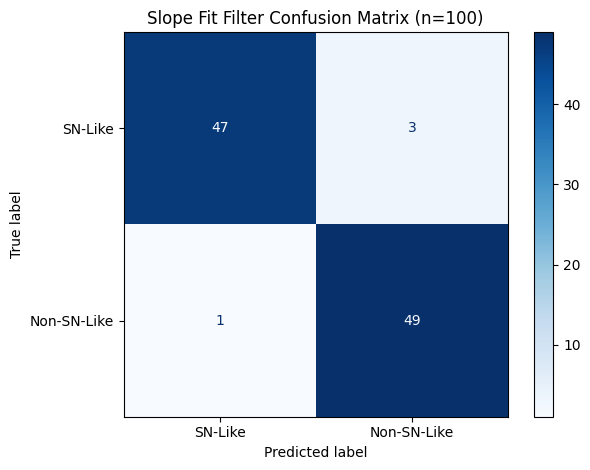

In [3]:
"""Making confusion matrices for the evaluation of slope fitting on 20 and 100 object sample tests."""
import matplotlib.pyplot as plt
import polars as pl
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# y_true: ground truth labels, e.g. "sn_like" / "non_sn_like" for each of your 100 objects
# y_pred: whether your filter passed or failed each object, e.g. "passed" / "failed"

n_sn_passed = len(sn_that_passed)
n_sn_failed = len(sn_that_did_not_pass)
n_non_sn_passed = len(non_sn_that_passed)
n_non_sn_failed = len(non_sn_that_did_not_pass)

y_true = (["detected"] * n_sn_passed + ["detected"] * n_sn_failed +
          ["not_detected"] * n_non_sn_passed + ["not_detected"] * n_non_sn_failed)

y_pred = (["detected"] * n_sn_passed + ["not_detected"] * n_sn_failed +
          ["detected"] * n_non_sn_passed + ["not_detected"] * n_non_sn_failed)


cm = confusion_matrix(y_true, y_pred, labels=["detected", "not_detected"])

disp = ConfusionMatrixDisplay(cm , display_labels=["SN-Like", "Non-SN-Like"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Slope Fit Filter Confusion Matrix (n=100)")
plt.tight_layout()
plt.savefig(Path.home() / "Documents"/"University"/"Honours"/"Honours_Project"/"images"/"slope_fitting"/"100_object_test" / "slope_fit_confusion_matrix_n_100.png")

In [7]:
"""Deduping a CSV"""
import polars as pl 

objects = pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/slope_fitting_results/objects_passing_slope_fit.csv")
objects = objects.unique(keep="first")
print (objects)
objects.write_csv("/home/riley/Documents/University/Honours/Honours_Project/data/slope_fitting_results/objects_passing_slope_fit.csv")

shape: (1_716, 1)
┌────────────────────┐
│ r:diaObjectId      │
│ ---                │
│ i64                │
╞════════════════════╡
│ 313761042204721198 │
│ 313853501446815761 │
│ 313853501307879455 │
│ 313967752695513096 │
│ 170028486135120047 │
│ …                  │
│ 313928194723938415 │
│ 313708289033502750 │
│ 313853517406142539 │
│ 313708289151467613 │
│ 313980945277911053 │
└────────────────────┘


In [16]:
""" Reading the parquet file of the light curve data of the 1000 SN objects that Anais sent me to add to the total data set."""

import polars as pl

PARQUET_PATH = "/home/riley/Documents/University/Honours/Honours_Project/data/2_photometry_passcuts.parquet"
TNS_OBJECTS = "/home/riley/Documents/University/Honours/Honours_Project/data/object_id_collection_results/candidates_in_TNS.csv"
SN_NEAR_GALAXY_OBJECTS = "/home/riley/Documents/University/Honours/Honours_Project/data/object_id_collection_results/sn_near_galaxy_candidate.csv"
EXTRAGALACTIC_OBJECTS = "/home/riley/Documents/University/Honours/Honours_Project/data/object_id_collection_results/extragalactic_lt20mag_candidate.csv"

objects = {"r:diaObjectId": []}

light_curve_data = pl.read_parquet(PARQUET_PATH)
for (object,), group in light_curve_data.group_by("diaObjectId"):
    objects["r:diaObjectId"].append(object)

objects_df = pl.DataFrame(objects)

object_ids = ((pl.read_csv(TNS_OBJECTS))).vstack(pl.read_csv(SN_NEAR_GALAXY_OBJECTS)).vstack(pl.read_csv(EXTRAGALACTIC_OBJECTS))
object_ids = object_ids.cast(pl.String).vstack(objects_df)
objects_ids = object_ids.unique(keep="first")
objects_ids.write_csv("/home/riley/Documents/University/Honours/Honours_Project/data/object_id_collection_results/all_objects.csv")

In [ ]:
"""Reading and appending light curve data to a parquet file from the curated sample from Anais"""
import polars as pl

PARQUET_PATH = "/home/riley/Documents/University/Honours/Honours_Project/data/2_photometry_passcuts.parquet"

EXISTING_LIGHT_CURVE_DATA = "/home/riley/Documents/University/Honours/Honours_Project/data/light_curve_data/combined_light_curve_data.parquet"

light_curve_data_1 = pl.read_parquet(PARQUET_PATH)
light_curve_data_2 = pl.read_parquet(EXISTING_LIGHT_CURVE_DATA).with_columns(pl.col("r:diaObjectId").cast(pl.String))

df1_fixed = (
    light_curve_data_1
    .rename({
        "diaObjectId":"r:diaObjectId",
        "diaSourceId":"r:diaSourceId",
        "midpointMjdTai":"r:midpointMjdTai",
        "band":"r:band",
        "psfFlux":"r:psfFlux",
        "psfFluxErr":"r:psfFluxErr",
    })
    .select([
        "r:diaObjectId",
        "r:diaSourceId",
        "r:midpointMjdTai",
        "r:band",
        "r:psfFlux",
        "r:psfFluxErr",
    ])
)

df_2 = light_curve_data_2.select([
        "r:diaObjectId",
        "r:diaSourceId",
        "r:midpointMjdTai",
        "r:band",
        "r:psfFlux",
        "r:psfFluxErr"])
print (df1_fixed)
print (df_2)
combined = pl.concat([df1_fixed, df_2], how="vertical")
pl.Config.set_tbl_rows(-1)
print (combined)

shape: (215_926, 6)
┌────────────────────┬────────────────────┬──────────────────┬────────┬─────────────┬──────────────┐
│ r:diaObjectId      ┆ r:diaSourceId      ┆ r:midpointMjdTai ┆ r:band ┆ r:psfFlux   ┆ r:psfFluxErr │
│ ---                ┆ ---                ┆ ---              ┆ ---    ┆ ---         ┆ ---          │
│ str                ┆ i64                ┆ f64              ┆ str    ┆ f64         ┆ f64          │
╞════════════════════╪════════════════════╪══════════════════╪════════╪═════════════╪══════════════╡
│ 170019696282173491 ┆ 170019696282173491 ┆ 61088.098045     ┆ r      ┆ 1392.86499  ┆ 156.502136   │
│ 170019696282173491 ┆ 170028485778079752 ┆ 61090.048021     ┆ i      ┆ 1329.658203 ┆ 222.340866   │
│ 170019696282173491 ┆ 170028486310232116 ┆ 61090.053976     ┆ i      ┆ 1691.847656 ┆ 237.187775   │
│ 170019696282173491 ┆ 170028487120781380 ┆ 61090.056576     ┆ i      ┆ 1673.970459 ┆ 225.461655   │
│ 170019696282173491 ┆ 170028487661322259 ┆ 61090.058342     ┆ i      ┆

In [4]:
"""Correctly deduping the light curve data based on the source id and not just the unique diaObjectIds"""

import polars as pl

COMBINED_LIGHT_CURVE_DATA = "/home/riley/Documents/University/Honours/Honours_Project/data/light_curve_data/combined_light_curve_data.parquet"

light_curve_data = pl.read_parquet(COMBINED_LIGHT_CURVE_DATA)

print ("Rows before:", light_curve_data.height)

duplicates = (
    light_curve_data
    .group_by("r:diaSourceId")
    .len()
    .filter(pl.col("len") > 1)
)

print(duplicates)

deduped_data = light_curve_data.unique(subset=["r:diaSourceId"], keep="first", maintain_order=True)

print ("Rows after:", deduped_data.height)
print ("Duplicates removed:", light_curve_data.height - deduped_data.height)

deduped_data["r:diaSourceId"].n_unique() == deduped_data.height

deduped_data.write_parquet(COMBINED_LIGHT_CURVE_DATA)

Rows before: 2501177
shape: (167_377, 2)
┌────────────────────┬─────┐
│ r:diaSourceId      ┆ len │
│ ---                ┆ --- │
│ i64                ┆ u32 │
╞════════════════════╪═════╡
│ 170063681331658891 ┆ 2   │
│ 170054927672934493 ┆ 2   │
│ 170028495983870051 ┆ 2   │
│ 170248393219113005 ┆ 2   │
│ 170059308876693512 ┆ 2   │
│ …                  ┆ …   │
│ 170054944705478765 ┆ 2   │
│ 170063680904888323 ┆ 2   │
│ 170028488914894925 ┆ 2   │
│ 170032914746572801 ┆ 2   │
│ 170032887741022236 ┆ 2   │
└────────────────────┴─────┘
Rows after: 2333800
Duplicates removed: 167377


In [1]:
"""Simple X match with known SN-like Objects"""

import polars as pl

SN_LIKE_OBJECTS = ["170028511067636654", 
"170019716323082348", 
"170032900274651160", 
"170032917163016282", 
"170046089928376424", 
"170235219334922248", 
"170261592629837872", 
"313699514821640259", 
"313835836426682441", 
"313945770546430083", 
"313963405286309936", 
"170257199649521669", 
"170411112000913487", 
"170028511473959008", 
"170094456357257301", 
"170094456400773135", 
"170226393328648251", 
"170230797176406143", 
"170296772058939493", 
"313765480704245975", 
"313831458352922664", 
"313871013530042570", 
"313928194288779300", 
"313932564866269223", 
"313932564880424967", 
"313932595758366765", 
"313936964384981047", 
"313945769043820590", 
"313945770525982796", 
"313950161909317636", 
"313958953395945530", 
"313963406691402058", 
"313967766285058088", 
"313980947917701210", 
"313985346353234012", 
"314011741926195228", 
"170032882395906068", 
"170274770629689377", 
"170274770656952330", 
"170274770671632438", 
"170389126953566274", 
"170433140735082813", 
"170433141132493221", 
"313708289017249906", 
"313708289051328625", 
"313761043604045880", 
"313783031112400976", 
"313831458447818885", 
"313831458523316231", 
"313853496686280764",
"313853497291309068"]

passing_sampling_objects = pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/sampling_results/sampling_pass.csv", schema_overrides={"r:diaObjectId": pl.String})

sn_like_sampling_objects = passing_sampling_objects.filter(pl.col("r:diaObjectId").is_in(SN_LIKE_OBJECTS))
pl.Config.set_tbl_rows(-1)
print (len(SN_LIKE_OBJECTS))
print (sn_like_sampling_objects)

51
shape: (35, 19)
┌─────────────────┬───────┬────────┬─────────┬───┬────────┬────────┬───────────────┬───────────────┐
│ r:diaObjectId   ┆ u pre ┆ u post ┆ g total ┆ … ┆ pass_g ┆ pass_z ┆ sampling_pass ┆ number_failed │
│ ---             ┆ ---   ┆ ---    ┆ ---     ┆   ┆ ---    ┆ ---    ┆ ---           ┆ ---           │
│ str             ┆ i64   ┆ i64    ┆ i64     ┆   ┆ bool   ┆ bool   ┆ bool          ┆ i64           │
╞═════════════════╪═══════╪════════╪═════════╪═══╪════════╪════════╪═══════════════╪═══════════════╡
│ 313708289051328 ┆ 0     ┆ 0      ┆ 10      ┆ … ┆ true   ┆ true   ┆ true          ┆ 0             │
│ 625             ┆       ┆        ┆         ┆   ┆        ┆        ┆               ┆               │
│ 170019716323082 ┆ 0     ┆ 0      ┆ 181     ┆ … ┆ true   ┆ true   ┆ true          ┆ 0             │
│ 348             ┆       ┆        ┆         ┆   ┆        ┆        ┆               ┆               │
│ 170411112000913 ┆ 4     ┆ 10     ┆ 13      ┆ … ┆ true   ┆ true   ┆ tru

In [3]:
import polars as pl 

# pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/salt_fitting/50_object_test/salt_phase_cuts_results/pass.csv").select([pl.col("n_peak_phase"), pl.col("n_shape_phase"), pl.col("n_g_colour"), pl.col("n_r_colour"), pl.col("n_i_colour"), pl.col("n_z_colour")]).describe([0.25, 0.5, 0.75, 0.9])
# pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/salt_fitting/50_object_test/chi2_requirements_results/chi2_requirement_values.csv").select([pl.col("g_chi2_per_point"), pl.col("r_chi2_per_point"), pl.col("i_chi2_per_point"), pl.col("z_chi2_per_point"), pl.col("reduced_chi2")]).describe([0.25, 0.5, 0.75, 0.9])
pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/salt_fitting/50_object_test/colour_stretch_results/pass.csv").select([pl.col("x1"), pl.col("x1_err"), pl.col("c"), pl.col("c_err")]).describe([0.25, 0.5, 0.75])


statistic,x1,x1_err,c,c_err
str,f64,f64,f64,f64
"""count""",5.0,5.0,5.0,5.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",0.106638,0.405976,-0.017848,0.026683
"""std""",0.468386,0.251754,0.072254,0.006526
"""min""",-0.628986,0.128355,-0.090669,0.018115
"""25%""",-0.057018,0.179717,-0.069781,0.022939
"""50%""",0.263734,0.44112,-0.047346,0.02741
"""75%""",0.408745,0.556197,0.051666,0.029708
"""max""",0.546715,0.724493,0.066889,0.035242


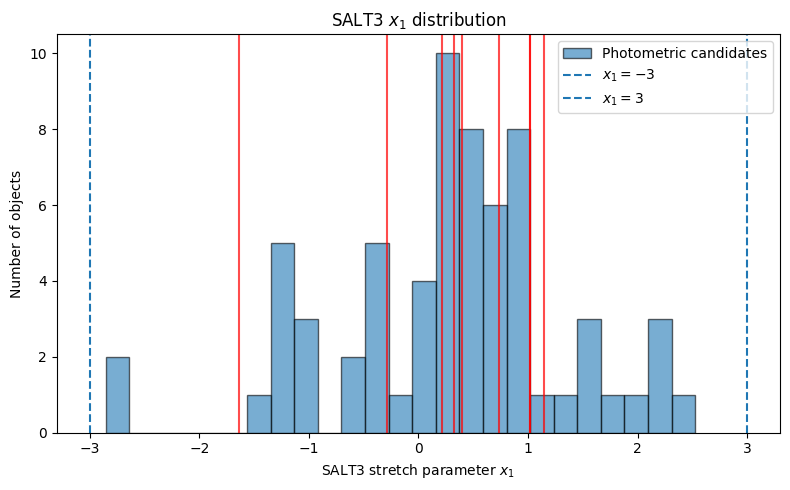

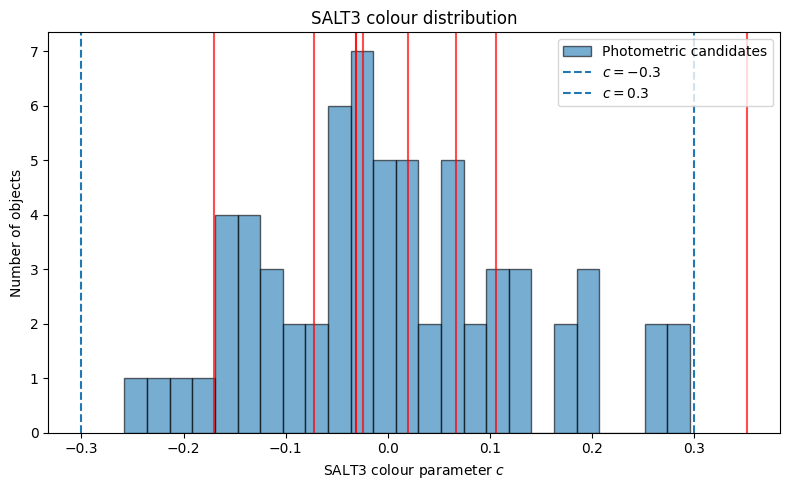

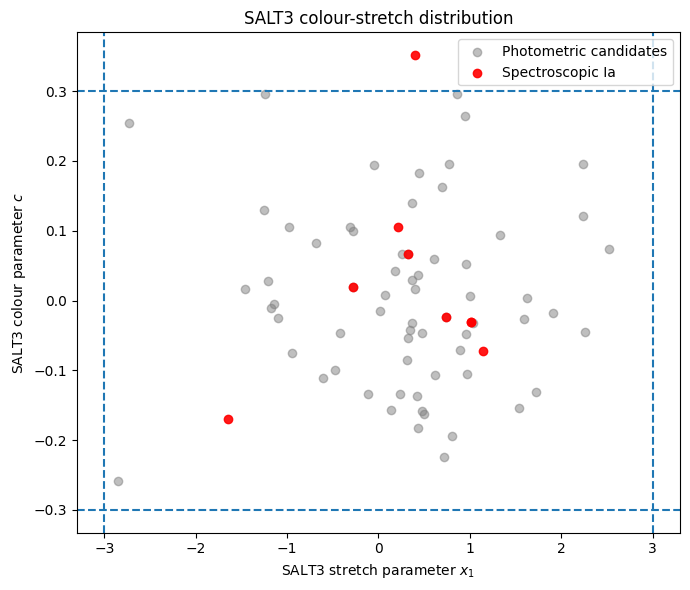

In [1]:
import matplotlib.pyplot as plt
import polars as pl

# Keep only valid fitted values
ia_results_df = pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/salt_fitting/confirmed_ia_tests/confirmed_ia_results.csv")
ia_plot_df = ia_results_df.filter(
    pl.col("x1").is_not_null()
    & pl.col("x1").is_finite()
    & pl.col("c").is_not_null()
    & pl.col("c").is_finite()
)

ia_x1 = ia_plot_df["x1"].to_numpy()
ia_c = ia_plot_df["c"].to_numpy()

results_df = pl.read_csv("/home/riley/Documents/University/Honours/Honours_Project/data/salt_fitting/with_z_results/colour_stretch_results/pass.csv")
plot_df = results_df.filter(
    pl.col("x1").is_not_null()
    & pl.col("x1").is_finite()
    & pl.col("c").is_not_null()
    & pl.col("c").is_finite()
)

x1 = plot_df["x1"].to_numpy()
c = plot_df["c"].to_numpy()


# ----------------------------------------------------------
# Stretch distribution
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    x1,
    bins=25,
    edgecolor="black",
    alpha=0.6,
    label="Photometric candidates",
)

for value in ia_x1:
    plt.axvline(
        value,
        color="red",
        alpha=0.7,
    )

plt.axvline(-3, linestyle="--", label=r"$x_1=-3$")
plt.axvline(3, linestyle="--", label=r"$x_1=3$")

plt.xlabel(r"SALT3 stretch parameter $x_1$")
plt.ylabel("Number of objects")
plt.title(r"SALT3 $x_1$ distribution")

plt.legend()
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Colour distribution
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    c,
    bins=25,
    edgecolor="black",
    alpha=0.6,
    label="Photometric candidates",
)

for value in ia_c:
    plt.axvline(
        value,
        color="red",
        alpha=0.7,
    )

plt.axvline(-0.3, linestyle="--", label=r"$c=-0.3$")
plt.axvline(0.3, linestyle="--", label=r"$c=0.3$")

plt.xlabel(r"SALT3 colour parameter $c$")
plt.ylabel("Number of objects")
plt.title(r"SALT3 colour distribution")

plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))

# Main photometric sample
plt.scatter(
    x1,
    c,
    color="grey",
    alpha=0.5,
    label="Photometric candidates",
)

# Spectroscopically confirmed Ia
plt.scatter(
    ia_x1,
    ia_c,
    color="red",
    alpha=0.9,
    label="Spectroscopic Ia",
    zorder=3,
)

plt.axvline(-3, linestyle="--")
plt.axvline(3, linestyle="--")

plt.axhline(-0.3, linestyle="--")
plt.axhline(0.3, linestyle="--")

plt.xlabel(r"SALT3 stretch parameter $x_1$")
plt.ylabel(r"SALT3 colour parameter $c$")
plt.title(r"SALT3 colour-stretch distribution")

plt.legend()
plt.tight_layout()
plt.show()

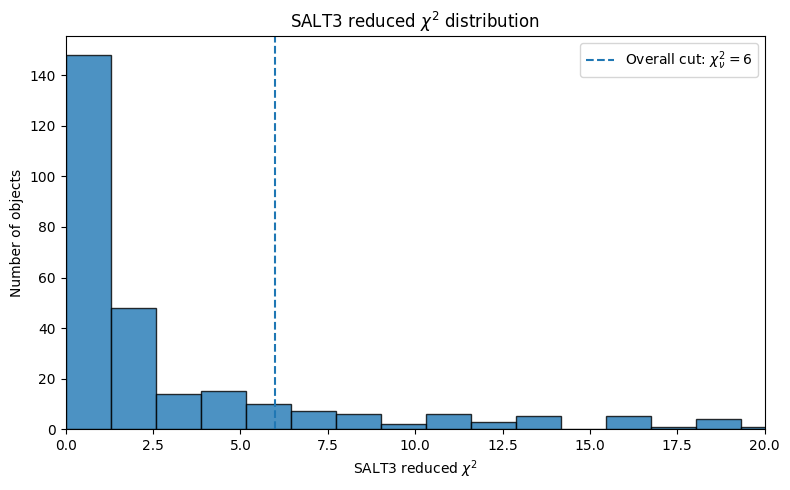

In [ ]:
chi2 = (
    results_df.filter(
        pl.col("reduced_chi2").is_not_null()
        & pl.col("reduced_chi2").is_finite()
        & (pl.col("reduced_chi2") >= 0)
    )["reduced_chi2"]
    .to_numpy()
)

plt.figure(figsize=(8, 5))

plt.hist(
    chi2,
    bins=3000,
    edgecolor="black",
    alpha=0.8,
)

plt.axvline(
    6,
    linestyle="--",
    label=r"Overall cut: $\chi^2_\nu = 6$",
)

plt.xlim(0, 20)

plt.xlabel(r"SALT3 reduced $\chi^2$")
plt.ylabel("Number of objects")
plt.title(r"SALT3 reduced $\chi^2$ distribution")

plt.legend()
plt.tight_layout()
plt.show()


In [15]:
import polars as pl

VISUAL_SN_THAT_DID_NOT_PASS_I_BAND = [
    "170028511473959008",
    "170032899789160499",
    "170032900274651160",
    "170032909192790198",
    "170046089928376424",
    "170094456334188639",
    "170094456357257301",
    "170094456365121569",
    "170094456400773135",
    "170226393328648251",
    "170230797176406143",
    "170235219334922248",
    "170261592629837872",
    "170270398108139547",
    "170411112000913487",
    "313629129584934928",
    "313699514821640259",
    "313703904917848098",
    "313708285409624132",
    "313708289051328625",
    "313756649400565795",
    "313756671823315162",
    "313761042284412983",
    "313765480559017992",
    "313765480514977875",
    "313765480704245975",
    "313769858758082631",
    "313783031112400976",
    "313783031917183090",
    "313831458352922664",
    "313831458536947728",
    "313835835847344147",
    "313835836251045940",
    "313835836426682441",
    "313853496550490147",
    "313853496554160141",
    "313853496686280764",
    "313853496765448219",
    "313853497287639046",
    "313853497291309068",
    "313853497321193628",
    "313853497352126507",
    "313853497540870166",
    "313853497577046043",
    "313853497580716135",
    "313853497987563541",
    "313853499363295265",
    "313853499427782700",
    "313853501446815761",
    "313853517466435621",
    "313853533265854510",
    "313862204793815182",
    "313871013530042570",
    "313871013678940198",
    "313871013794283597",
    "313871014435488133",
    "313879818462560268",
    "313879818492444691",
    "313888627043598349",
    "313888627070337103",
    "313893022930567256",
    "313897381686411345",
    "313897383783038984",
    "313897383967588462",
    "313928193953234970",
    "313928194151940140",
    "313928194157183045",
    "313928194187591742",
    "313928194288779300",
    "313928194477522960",
    "313928194567700757",
    "313928194702966808",
    "313932564806500404",
    "313932564866269223",
    "313932564880424967",
    "313936964384981047",
    "313941448959459395",
    "313945770525982796",
    "313945770546430083",
    "313950161909317636",
    "313963357429825638",
    "313963357436117032",
    "313963359364448306",
    "313963359491850270",
    "313963405222871043",
    "313963405286309936",
    "313963406691402058",
    "313967752817672227",
    "313967766147694664",
    "313967766270378010",
    "313967766285058088",
    "313967767217766555",
    "313972153287442489",
    "313980945119576112",
    "313980947917701210",
    "313985346353234012",
    "313998569640558678",
    "314003014107006318",
    "314051320244339039",
]

def load_band_flags(
    pass_path: str,
    fail_path: str,
    band: str,
) -> pl.DataFrame:

    passed = (
        pl.read_csv(
            pass_path,
            schema_overrides={"r:diaObjectId": pl.String},
        )
        .select("r:diaObjectId")
        .with_columns(
            pl.lit(True).alias(f"{band}_pass")
        )
    )

    failed = (
        pl.read_csv(
            fail_path,
            schema_overrides={"r:diaObjectId": pl.String},
        )
        .select("r:diaObjectId")
        .with_columns(
            pl.lit(False).alias(f"{band}_pass")
        )
    )

    return pl.concat(
        [passed, failed],
        how="vertical",
    )

g = load_band_flags(
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/g_band/pass.csv",
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/g_band/fail.csv",
    "g",
)

r = load_band_flags(
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/r_band/pass.csv",
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/r_band/fail.csv",
    "r",
)

i = load_band_flags(
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/i_band/pass.csv",
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/i_band/fail.csv",
    "i",
)

z = load_band_flags(
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/z_band/pass.csv",
    "/home/riley/Documents/University/Honours/Honours_Project/data/constant_minus_shape_results/z_band/fail.csv",
    "z",
)

combined = (
    g.join(r, on="r:diaObjectId", how="full", coalesce=True)
    .join(i, on="r:diaObjectId", how="full", coalesce=True)
    .join(z, on="r:diaObjectId", how="full", coalesce=True)
)

combined = combined.with_columns(
    pl.sum_horizontal(
        pl.col("g_pass").fill_null(False),
        pl.col("r_pass").fill_null(False),
        pl.col("i_pass").fill_null(False),
        pl.col("z_pass").fill_null(False),
    ).alias("number_bands_passed"),

    pl.any_horizontal(
        pl.col("g_pass").fill_null(False),
        pl.col("r_pass").fill_null(False),
        pl.col("i_pass").fill_null(False),
        pl.col("z_pass").fill_null(False),
    ).alias("any_band_pass"),
)

print(
    combined.select(
        pl.col("g_pass").fill_null(False).sum().alias("g_passes"),
        pl.col("r_pass").fill_null(False).sum().alias("r_passes"),
        pl.col("i_pass").fill_null(False).sum().alias("i_passes"),
        pl.col("z_pass").fill_null(False).sum().alias("z_passes"),
        pl.col("any_band_pass").sum().alias("any_band_passes"),
    )
)

rescued = combined.filter(
    ~pl.col("i_pass").fill_null(False)
    & pl.col("any_band_pass")
)

print("Objects rescued relative to i-only:", rescued.height)

print(
    rescued.select(
        pl.col("g_pass").fill_null(False).sum().alias("rescued_by_g"),
        pl.col("r_pass").fill_null(False).sum().alias("rescued_by_r"),
        pl.col("z_pass").fill_null(False).sum().alias("rescued_by_z"),
    )
)

validation = combined.filter(
    pl.col("r:diaObjectId").is_in(VISUAL_SN_THAT_DID_NOT_PASS_I_BAND)
)

print(
    validation.select(
        pl.col("i_pass")
        .fill_null(False)
        .sum()
        .alias("pass_i_only"),

        pl.col("any_band_pass")
        .fill_null(False)
        .sum()
        .alias("pass_any_band"),
    )
)

rescued_sn_like = validation.filter(
    pl.col("g_pass").fill_null(False)
    | pl.col("r_pass").fill_null(False)
    | pl.col("z_pass").fill_null(False))

print(
    f"Visually SN-like i-band failures rescued by another band: "
    f"{rescued_sn_like.height}/{validation.height}"
)

shape: (1, 5)
┌──────────┬──────────┬──────────┬──────────┬─────────────────┐
│ g_passes ┆ r_passes ┆ i_passes ┆ z_passes ┆ any_band_passes │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---             │
│ u32      ┆ u32      ┆ u32      ┆ u32      ┆ u32             │
╞══════════╪══════════╪══════════╪══════════╪═════════════════╡
│ 1761     ┆ 1788     ┆ 1542     ┆ 644      ┆ 2577            │
└──────────┴──────────┴──────────┴──────────┴─────────────────┘
Objects rescued relative to i-only: 1035
shape: (1, 3)
┌──────────────┬──────────────┬──────────────┐
│ rescued_by_g ┆ rescued_by_r ┆ rescued_by_z │
│ ---          ┆ ---          ┆ ---          │
│ u32          ┆ u32          ┆ u32          │
╞══════════════╪══════════════╪══════════════╡
│ 713          ┆ 613          ┆ 76           │
└──────────────┴──────────────┴──────────────┘
shape: (1, 2)
┌─────────────┬───────────────┐
│ pass_i_only ┆ pass_any_band │
│ ---         ┆ ---           │
│ u32         ┆ u32           │
╞═══════════